## ACL_Team70


## 0. Setup

### 0.1 Imports
For now we only need the basic data and plotting libraries. We will import the modeling libraries (sklearn, SHAP, LIME, ...) later, in the sections that use them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# show all columns when we print a table
pd.set_option("display.max_columns", None)

# same look for all plots
sns.set_style("whitegrid")

### 0.2 Loading the 14 tables

In [2]:
DATA_PATH = "f1_dataset/"

circuits              = pd.read_csv(DATA_PATH + "circuits.csv")
constructors          = pd.read_csv(DATA_PATH + "constructors.csv")
constructor_results   = pd.read_csv(DATA_PATH + "constructor_results.csv")
constructor_standings = pd.read_csv(DATA_PATH + "constructor_standings.csv")
drivers               = pd.read_csv(DATA_PATH + "drivers.csv")
driver_standings      = pd.read_csv(DATA_PATH + "driver_standings.csv")
lap_times             = pd.read_csv(DATA_PATH + "lap_times.csv")
pit_stops             = pd.read_csv(DATA_PATH + "pit_stops.csv")
qualifying            = pd.read_csv(DATA_PATH + "qualifying.csv")
races                 = pd.read_csv(DATA_PATH + "races.csv")
results               = pd.read_csv(DATA_PATH + "results.csv")
seasons               = pd.read_csv(DATA_PATH + "seasons.csv")
sprint_results        = pd.read_csv(DATA_PATH + "sprint_results.csv")
status                = pd.read_csv(DATA_PATH + "status.csv")

# put all tables in one dictionary so we can loop over them in the EDA
tables = {
    "circuits": circuits,
    "constructors": constructors,
    "constructor_results": constructor_results,
    "constructor_standings": constructor_standings,
    "drivers": drivers,
    "driver_standings": driver_standings,
    "lap_times": lap_times,
    "pit_stops": pit_stops,
    "qualifying": qualifying,
    "races": races,
    "results": results,
    "seasons": seasons,
    "sprint_results": sprint_results,
    "status": status,
}

print("Loaded", len(tables), "tables")

Loaded 14 tables


## 1. Initial EDA (raw data, before cleaning)

First we get to know the 14 tables as they are: how big each one is, what columns it has, and what the values look like.

In [3]:
shapes = []
for name in tables:
    df = tables[name]
    shapes.append([name, df.shape[0], df.shape[1]])

shapes = pd.DataFrame(shapes, columns=["table", "rows", "columns"])
shapes.sort_values("rows", ascending=False)

,table,rows,columns
6,lap_times,589081,6
5,driver_standings,34863,7
10,results,26759,18
3,constructor_standings,13391,7
2,constructor_results,12625,5
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18
4,drivers,861,9
12,sprint_results,360,16


For each table we print `info()` (column types and non-null counts) and the first 10 rows.

Note: `info()` will show almost no nulls here, because missing values are still written as the text `\N`. Columns that should be numbers or dates may also show up as `object` (text) for the same reason. We fix this in the cleaning section.

In [4]:
for name in tables:
    df = tables[name]
    print("=" * 60)
    print(name.upper(), "-", df.shape[0], "rows,", df.shape[1], "columns")
    print("=" * 60)
    df.info()
    display(df.head(5))

CIRCUITS - 77 rows, 9 columns
<class 'pandas.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     str    
 2   name        77 non-null     str    
 3   location    77 non-null     str    
 4   country     77 non-null     str    
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     str    
dtypes: float64(2), int64(2), str(5)
memory usage: 5.5 KB


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park


CONSTRUCTORS - 212 rows, 5 columns
<class 'pandas.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   constructorId   212 non-null    int64
 1   constructorRef  212 non-null    str  
 2   name            212 non-null    str  
 3   nationality     212 non-null    str  
 4   url             212 non-null    str  
dtypes: int64(1), str(4)
memory usage: 8.4 KB


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


CONSTRUCTOR_RESULTS - 12625 rows, 5 columns
<class 'pandas.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                12625 non-null  str    
dtypes: float64(1), int64(3), str(1)
memory usage: 493.3 KB


...

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


SPRINT_RESULTS - 360 rows, 16 columns
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   resultId        360 non-null    int64
 1   raceId          360 non-null    int64
 2   driverId        360 non-null    int64
 3   constructorId   360 non-null    int64
 4   number          360 non-null    int64
 5   grid            360 non-null    int64
 6   position        360 non-null    str  
 7   positionText    360 non-null    str  
 8   positionOrder   360 non-null    int64
 9   points          360 non-null    int64
 10  laps            360 non-null    int64
 11  time            360 non-null    str  
 12  milliseconds    360 non-null    str  
 13  fastestLap      360 non-null    str  
 14  fastestLapTime  360 non-null    str  
 15  statusId        360 non-null    int64
dtypes: int64(10), str(6)
memory usage: 45.1 KB


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


STATUS - 139 rows, 2 columns
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   statusId  139 non-null    int64
 1   status    139 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.3 KB


,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine


**What the raw data shows**
- 6 of the 14 tables use the text `\N` for missing values (drivers, constructor_results, qualifying, races, results, sprint_results). Because of this, `info()` reports these columns as non-null, so the real number of missing values is hidden.
- Many columns that should be numbers are read as text (`str`) only because they contain `\N`. For example, in `results`: position, milliseconds, fastestLap, rank, fastestLapTime and fastestLapSpeed.
- `qualifying` q2 and q3 contain two kinds of missing at once: the text `\N` and real empty cells (22 and 46 rows).
- Times are stored as text in 3 formats: `"1:26.572"` (lap/qualifying), `"1:34:50.616"` (race time) and `"26.898"` (pit duration). They need converting to seconds.
- Dates (`races.date`, `drivers.dob`) are text and need converting to datetime.

Next we count the `\N` values in every column to see how much data is actually missing.

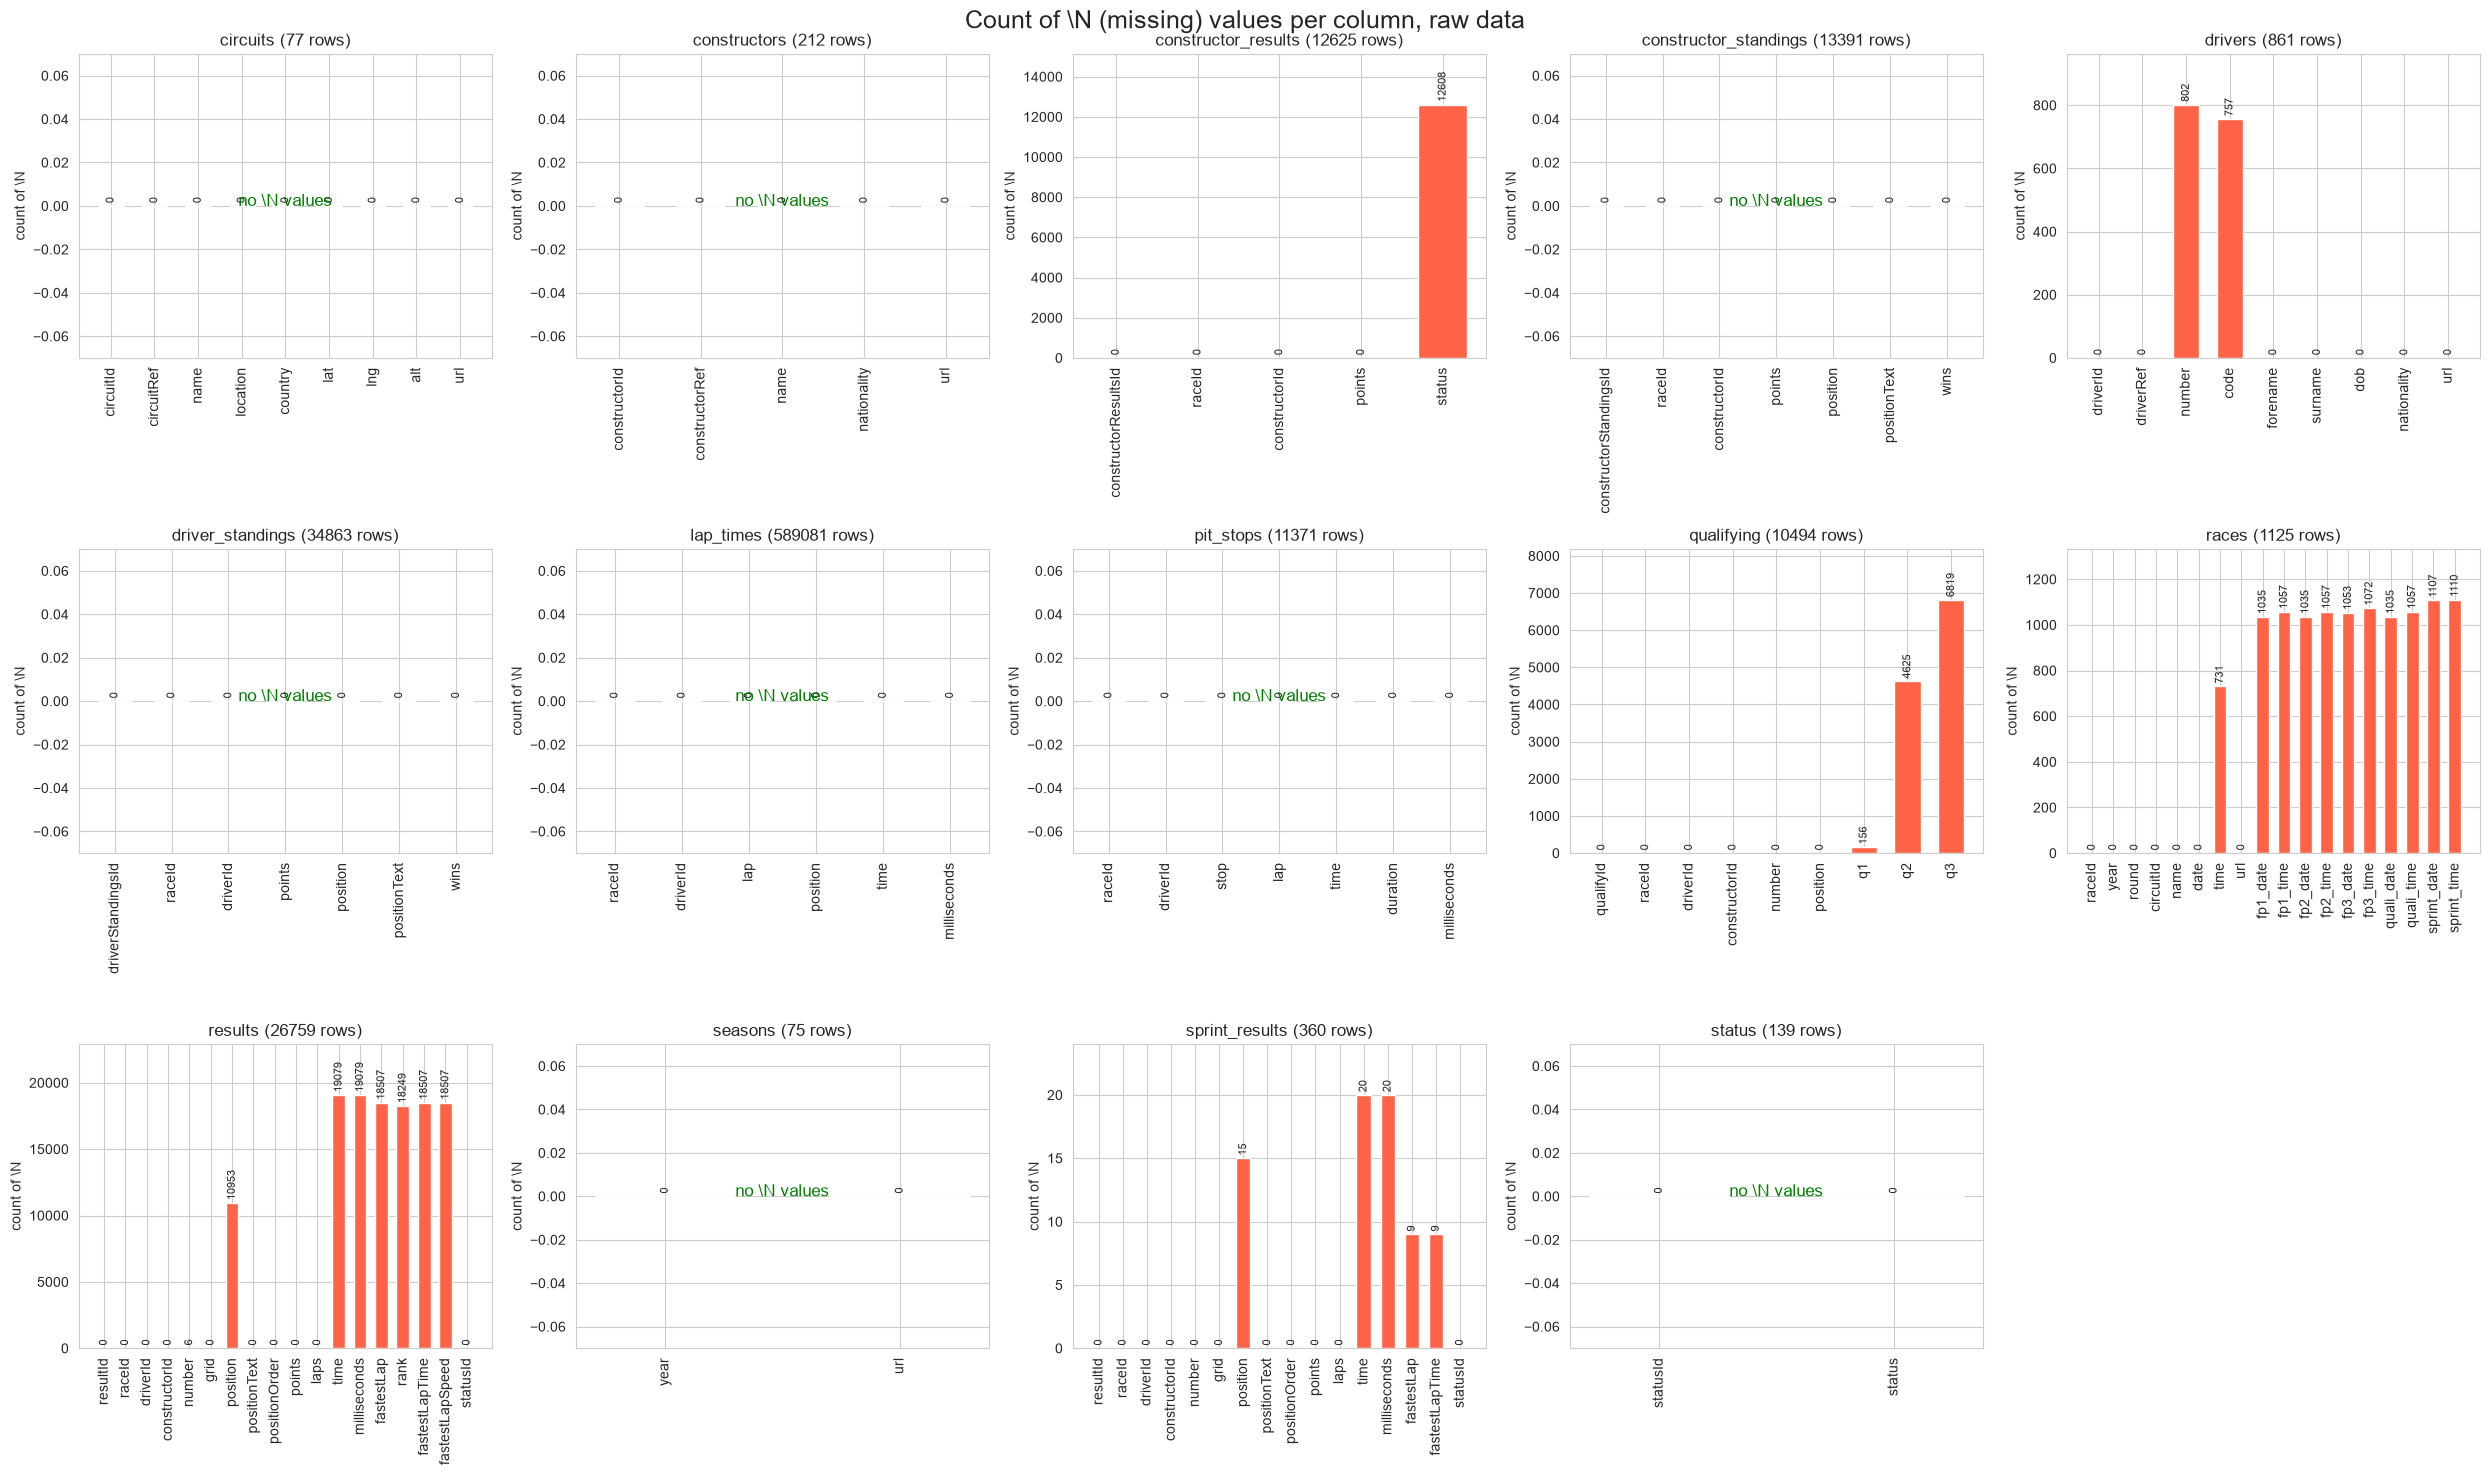

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(25, 15))
axes = axes.flatten()   # turn the 3x5 grid into a simple list of 15 plots

i = 0
for name in tables:
    df = tables[name]
    ax = axes[i]

    # count how many cells in each column are exactly the text \N
    n_count = (df == "\\N").sum()

    bars = ax.bar(n_count.index, n_count.values, color="tomato", width=0.6)
    ax.bar_label(bars, fontsize=8, rotation=90, padding=2)
    ax.margins(y=0.2)


    ax.set_title(name + " (" + str(len(df)) + " rows)")
    ax.set_ylabel("count of \\N")
    ax.tick_params(axis="x", rotation=90)

    if n_count.sum() == 0:
        ax.text(0.5, 0.5, "no \\N values", transform=ax.transAxes,
                ha="center", fontsize=12, color="green")

    i = i + 1

# we have 14 tables but 15 slots, so hide the last empty one
axes[14].axis("off")

plt.suptitle("Count of \\N (missing) values per column, raw data", fontsize=18)
plt.tight_layout()
plt.show()

### Duplicate check

We check two kinds of duplicates in every table:
- **Full-row duplicates**: two rows that are identical in every column.
- **Duplicate key**: two rows that share the column(s) that should identify one row (for example, the same driver appearing twice in the same race in `results`). The rows can differ in other columns, so a full-row check would not catch this.

The count shows the extra copies only (the first occurrence is not counted).

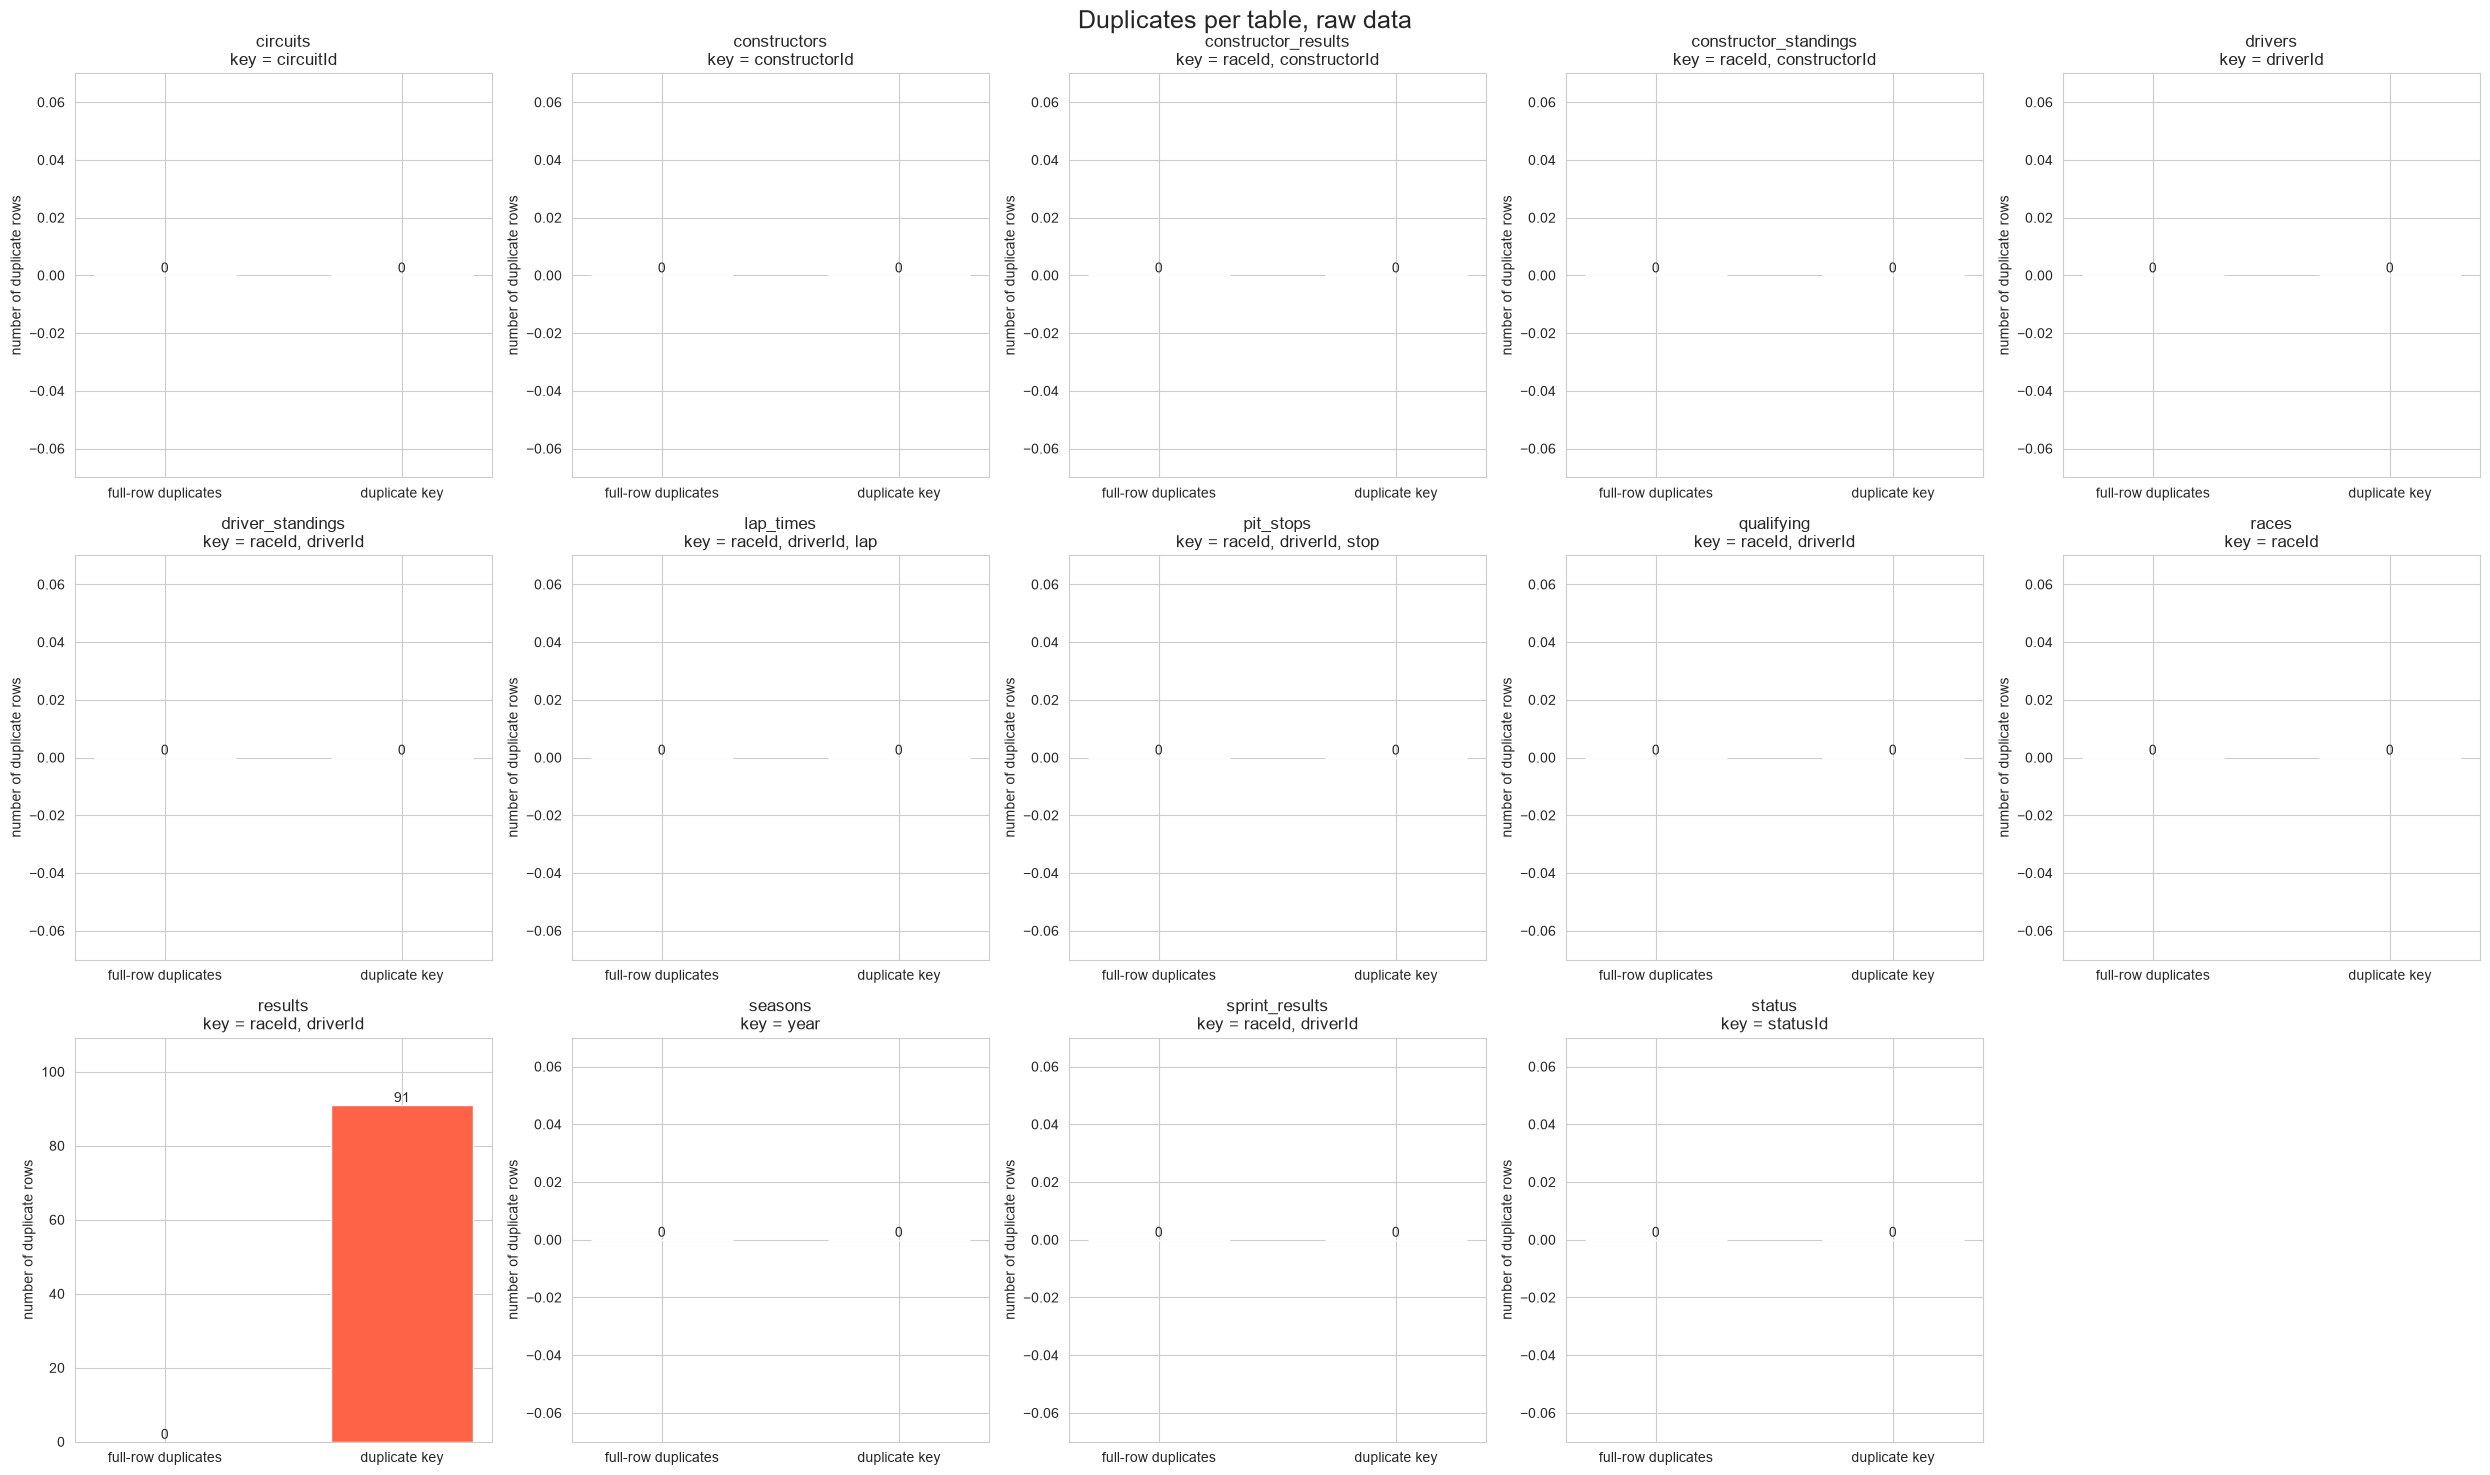

,table,key,full_row_duplicates,duplicate_key
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,"raceId, constructorId",0,0
3,constructor_standings,"raceId, constructorId",0,0
4,drivers,driverId,0,0
5,driver_standings,"raceId, driverId",0,0
6,lap_times,"raceId, driverId, lap",0,0
7,pit_stops,"raceId, driverId, stop",0,0
8,qualifying,"raceId, driverId",0,0
9,races,raceId,0,0


In [6]:
# the column(s) that should identify exactly one row in each table
keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["raceId", "constructorId"],
    "constructor_standings": ["raceId", "constructorId"],
    "drivers": ["driverId"],
    "driver_standings": ["raceId", "driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["raceId", "driverId"],
    "races": ["raceId"],
    "results": ["raceId", "driverId"],
    "seasons": ["year"],
    "sprint_results": ["raceId", "driverId"],
    "status": ["statusId"],
}

fig, axes = plt.subplots(3, 5, figsize=(25, 15))
axes = axes.flatten()

dup_summary = []
i = 0
for name in tables:
    df = tables[name]
    ax = axes[i]

    full_dups = df.duplicated().sum()
    key_dups = df.duplicated(subset=keys[name]).sum()
    dup_summary.append([name, ", ".join(keys[name]), full_dups, key_dups])

    bars = ax.bar(["full-row duplicates", "duplicate key"], [full_dups, key_dups],
                  color=["steelblue", "tomato"], width=0.6)
    ax.bar_label(bars, fontsize=10)
    ax.set_title(name + "\nkey = " + ", ".join(keys[name]))
    ax.set_ylabel("number of duplicate rows")
    ax.margins(y=0.2)

    i = i + 1

axes[14].axis("off")

plt.suptitle("Duplicates per table, raw data", fontsize=18)
plt.tight_layout()
plt.show()

dup_summary = pd.DataFrame(dup_summary, columns=["table", "key", "full_row_duplicates", "duplicate_key"])
dup_summary

#### Duplicate (raceId, driverId) in `results`

Our modeling table needs exactly one row per driver per race. Here we look at the rows that break this: how many there are, which years they come from, and what they look like. We expect them to come from the **shared drives** of early F1 (until 1957), when a driver could take over a teammate's car mid-race. That gives the same driver one result row per car he drove.

Rows involved in a duplicate (raceId, driverId): 176
Number of (raceId, driverId) pairs that repeat: 85


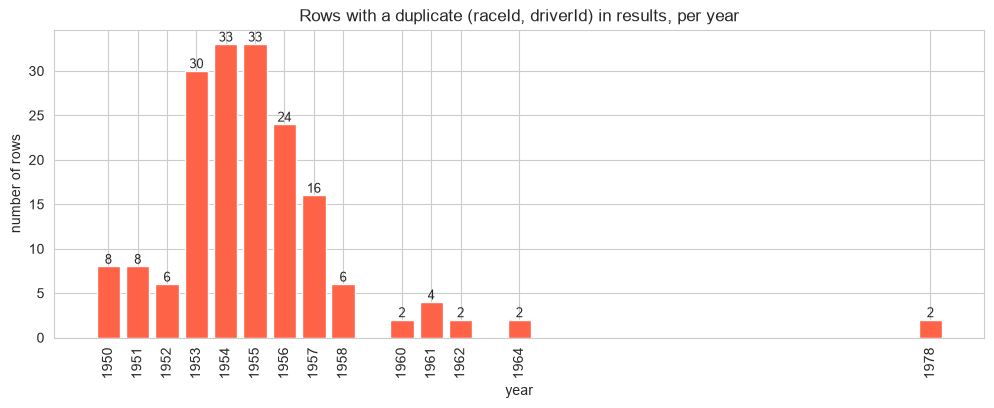

In [7]:
# keep=False marks ALL rows of a repeated pair (not only the extra copies)
dup_mask = results.duplicated(subset=["raceId", "driverId"], keep=False)
dup_results = results[dup_mask]

n_pairs = len(dup_results[["raceId", "driverId"]].drop_duplicates())
print("Rows involved in a duplicate (raceId, driverId):", len(dup_results))
print("Number of (raceId, driverId) pairs that repeat:", n_pairs)

# add the year and race name so we can see when these happened
dup_results = dup_results.merge(races[["raceId", "year", "name"]], on="raceId")

dup_per_year = dup_results.groupby("year")["resultId"].count()

plt.figure(figsize=(12, 4))
bars = plt.bar(dup_per_year.index, dup_per_year.values, color="tomato")
plt.bar_label(bars, fontsize=9)
plt.title("Rows with a duplicate (raceId, driverId) in results, per year")
plt.xlabel("year")
plt.ylabel("number of rows")
plt.xticks(dup_per_year.index, rotation=90)
plt.show()

In [8]:
# show some examples with the driver's name, to see what the repeated rows look like
examples = dup_results.merge(drivers[["driverId", "forename", "surname"]], on="driverId")
examples = examples.sort_values(["raceId", "driverId"])

examples[["year", "name", "forename", "surname", "constructorId", "number",
          "grid", "positionOrder", "positionText", "laps", "points"]].head(6)

,year,name,forename,surname,constructorId,number,grid,positionOrder,positionText,laps,points
0,1978,Italian Grand Prix,Harald,Ertl,54,10,0,26,F,0,0.0
1,1978,Italian Grand Prix,Harald,Ertl,57,23,0,29,F,0,0.0
2,1964,United States Grand Prix,Jim,Clark,172,1,1,7,7,102,0.0
175,1964,United States Grand Prix,Jim,Clark,172,2,1,12,R,54,0.0
3,1962,British Grand Prix,Keith,Greene,172,48,0,22,W,0,0.0
4,1962,British Grand Prix,Keith,Greene,97,50,0,25,W,0,0.0


**Duplicate rule:** `results` has 85 repeated (raceId, driverId) pairs (176 rows, 91 extra). Most come from the 1950s shared drives. A few later ones are drivers entered with two cars/teams in the same race (e.g. Ertl 1978, who failed to qualify in both). For every pair we keep the row with the **best (lowest) `positionOrder`** and drop the others.

**Why:** a driver's result in a race is the best result among the cars he drove, and that row decides whether he reached the podium (our target). The rule is simple and gives the same result every time it runs.

We apply it to a copy (`results_clean`), so the raw table stays unchanged.

In [9]:
# sort so the best positionOrder comes first, then keep only the first row of each (raceId, driverId)
results_clean = results.sort_values(["raceId", "driverId", "positionOrder"])
results_clean = results_clean.drop_duplicates(subset=["raceId", "driverId"], keep="first")

print("Rows before:", len(results))
print("Rows after: ", len(results_clean))
print("Rows removed:", len(results) - len(results_clean))
print("Duplicate (raceId, driverId) left:", results_clean.duplicated(subset=["raceId", "driverId"]).sum())

Rows before: 26759
Rows after:  26668
Rows removed: 91
Duplicate (raceId, driverId) left: 0


### Primary key check

A primary key is the column (or columns) that uniquely identifies each row in a table. For each table we check that its primary key has **no duplicate values** and **no missing values**. Tables without a single ID column (`lap_times`, `pit_stops`) use a combination of columns.

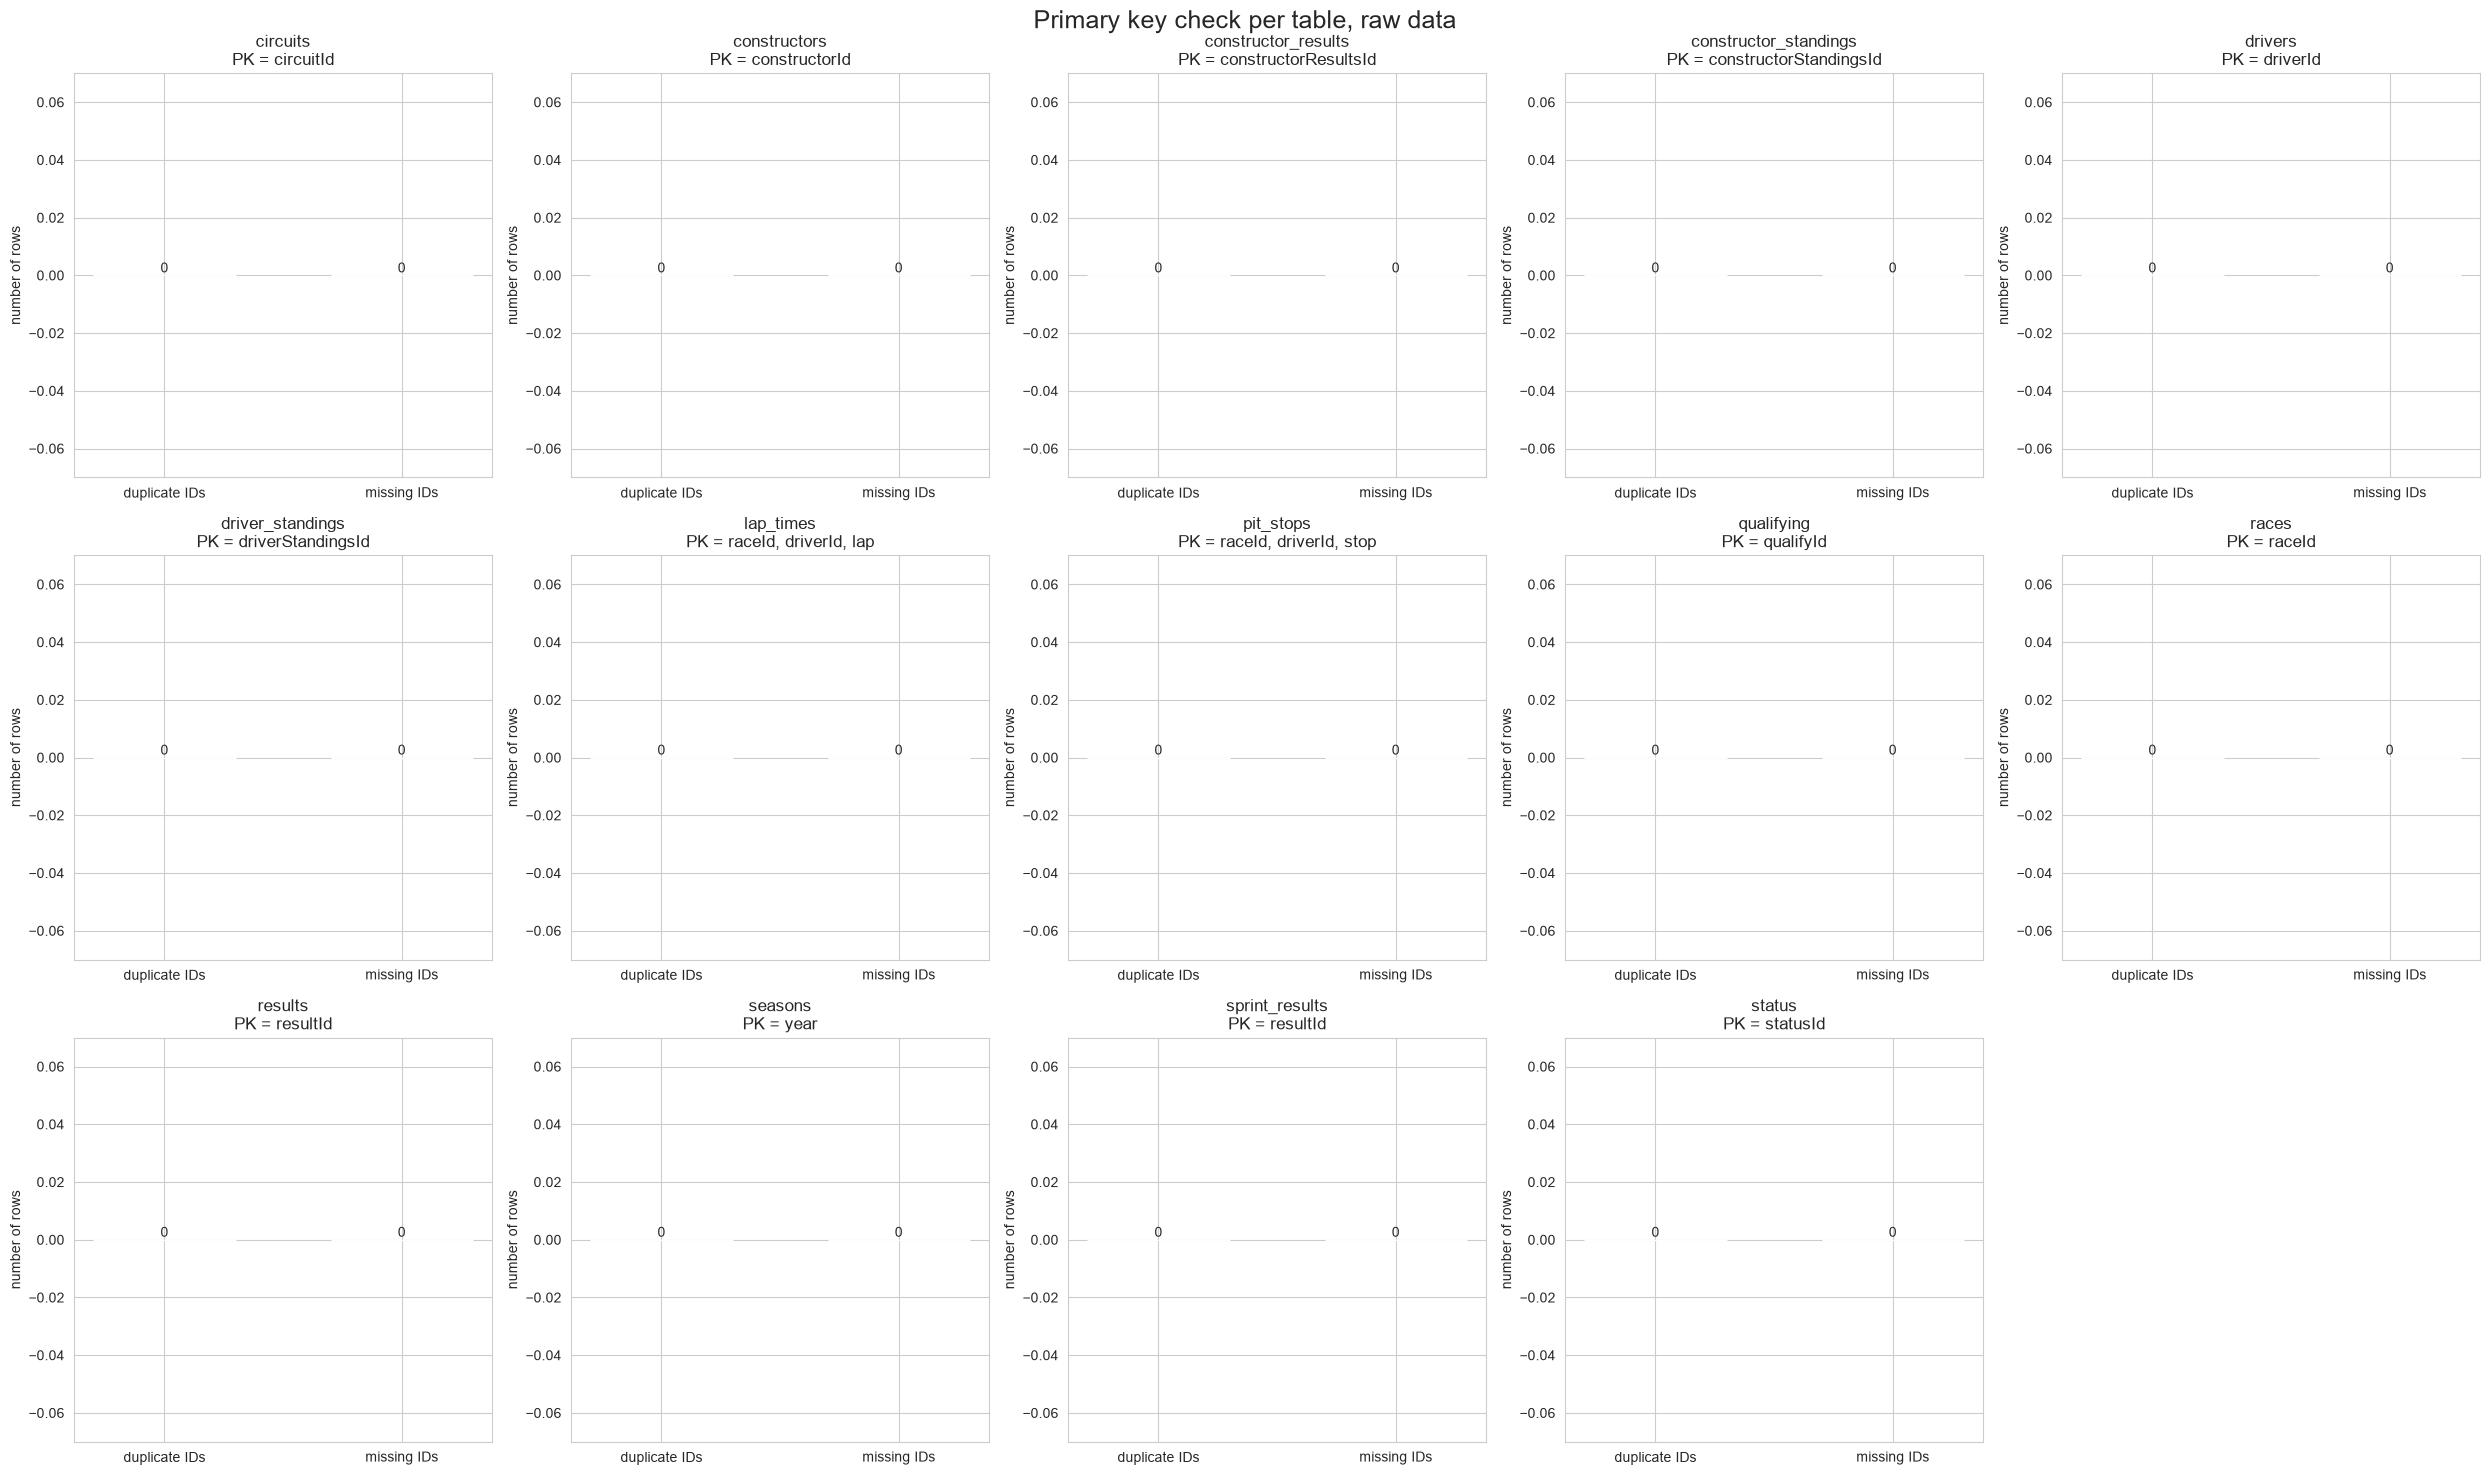

,table,primary_key,duplicate_ids,missing_ids
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,lap_times,"raceId, driverId, lap",0,0
7,pit_stops,"raceId, driverId, stop",0,0
8,qualifying,qualifyId,0,0
9,races,raceId,0,0


In [10]:
# the primary key of each table
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"],
}

fig, axes = plt.subplots(3, 5, figsize=(25, 15))
axes = axes.flatten()

pk_summary = []
i = 0
for name in tables:
    df = tables[name]
    pk = primary_keys[name]
    ax = axes[i]

    duplicate_ids = df.duplicated(subset=pk).sum()
    missing_ids = df[pk].isnull().any(axis=1).sum()   # rows where any key column is missing
    pk_summary.append([name, ", ".join(pk), duplicate_ids, missing_ids])

    bars = ax.bar(["duplicate IDs", "missing IDs"], [duplicate_ids, missing_ids],
                  color=["steelblue", "tomato"], width=0.6)
    ax.bar_label(bars, fontsize=10)
    ax.set_title(name + "\nPK = " + ", ".join(pk))
    ax.set_ylabel("number of rows")
    ax.margins(y=0.2)

    i = i + 1

axes[14].axis("off")

plt.suptitle("Primary key check per table, raw data", fontsize=18)
plt.tight_layout()
plt.show()

pk_summary = pd.DataFrame(pk_summary, columns=["table", "primary_key", "duplicate_ids", "missing_ids"])
pk_summary

### Foreign key check

A foreign key is a column that points to the primary key of another table (for example, `results.driverId` points to `drivers.driverId`). For every foreign key we count the rows whose value **does not exist** in the table it points to. Such rows would be lost, or filled with NaN, when we join the tables.

9 of the 14 tables have foreign keys, so this figure uses a 2x5 grid.

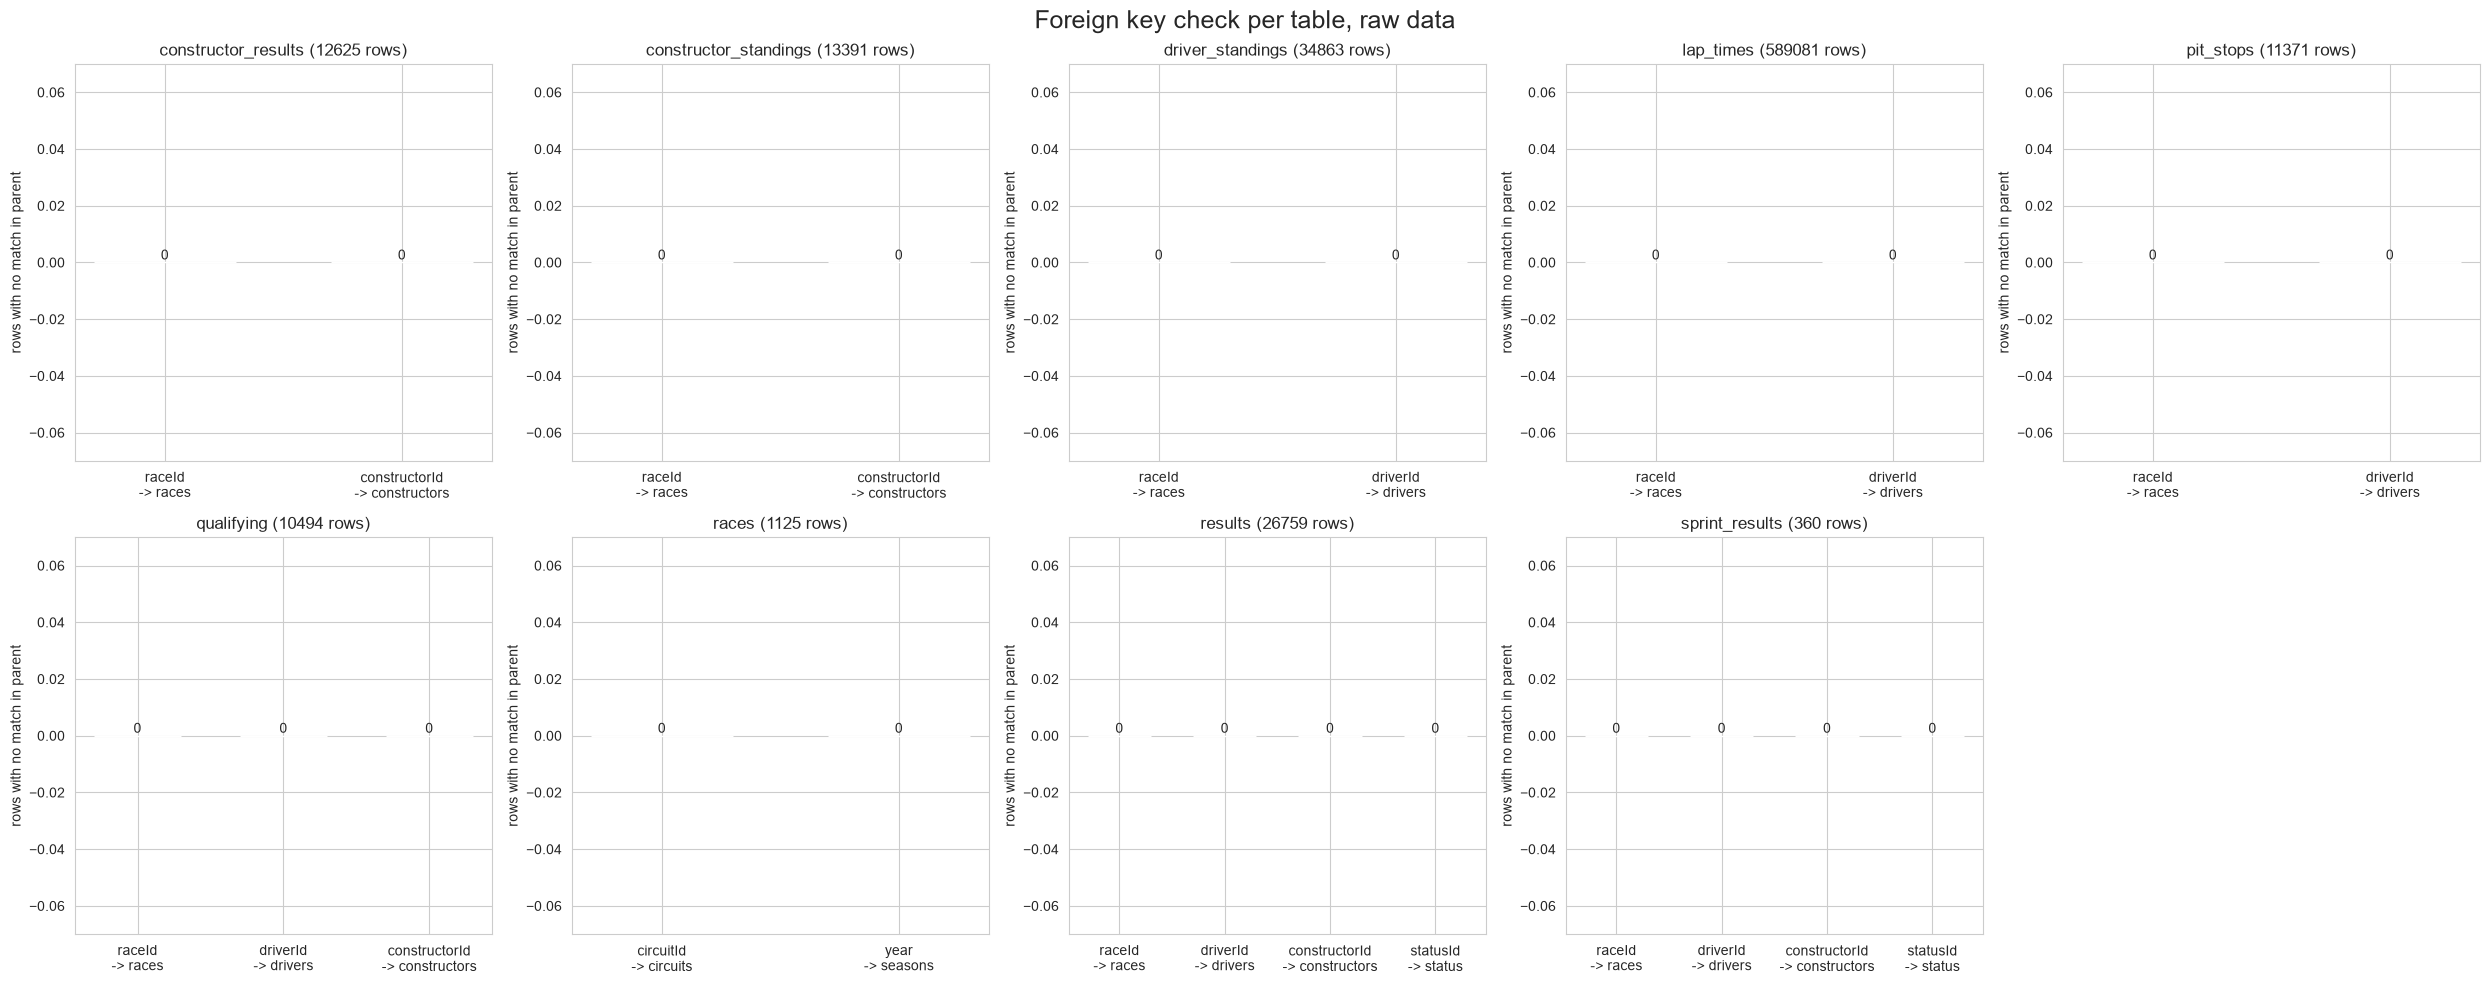

,table,foreign_key,points_to,rows_not_found
0,constructor_results,raceId,races,0
1,constructor_results,constructorId,constructors,0
2,constructor_standings,raceId,races,0
3,constructor_standings,constructorId,constructors,0
4,driver_standings,raceId,races,0
5,driver_standings,driverId,drivers,0
6,lap_times,raceId,races,0
7,lap_times,driverId,drivers,0
8,pit_stops,raceId,races,0
9,pit_stops,driverId,drivers,0


In [11]:
# for each table: {foreign key column: table it points to}
# (the column has the same name in both tables)
foreign_keys = {
    "constructor_results":   {"raceId": "races", "constructorId": "constructors"},
    "constructor_standings": {"raceId": "races", "constructorId": "constructors"},
    "driver_standings":      {"raceId": "races", "driverId": "drivers"},
    "lap_times":             {"raceId": "races", "driverId": "drivers"},
    "pit_stops":             {"raceId": "races", "driverId": "drivers"},
    "qualifying":            {"raceId": "races", "driverId": "drivers", "constructorId": "constructors"},
    "races":                 {"circuitId": "circuits", "year": "seasons"},
    "results":               {"raceId": "races", "driverId": "drivers", "constructorId": "constructors", "statusId": "status"},
    "sprint_results":        {"raceId": "races", "driverId": "drivers", "constructorId": "constructors", "statusId": "status"},
}

fig, axes = plt.subplots(2, 5, figsize=(25, 10))
axes = axes.flatten()

fk_summary = []
i = 0
for name in foreign_keys:
    df = tables[name]
    ax = axes[i]

    labels = []
    counts = []
    for column in foreign_keys[name]:
        parent_name = foreign_keys[name][column]
        parent = tables[parent_name]

        # True for rows whose value is NOT found in the parent table
        not_found = ~df[column].isin(parent[column])
        n_missing = not_found.sum()

        labels.append(column + "\n-> " + parent_name)
        counts.append(n_missing)
        fk_summary.append([name, column, parent_name, n_missing])

    bars = ax.bar(labels, counts, color="tomato", width=0.6)
    ax.bar_label(bars, fontsize=10)
    ax.set_title(name + " (" + str(len(df)) + " rows)")
    ax.set_ylabel("rows with no match in parent")
    ax.margins(y=0.2)

    i = i + 1

# 9 tables but 10 slots, so hide the last empty one
axes[9].axis("off")

plt.suptitle("Foreign key check per table, raw data", fontsize=18)
plt.tight_layout()
plt.show()

fk_summary = pd.DataFrame(fk_summary, columns=["table", "foreign_key", "points_to", "rows_not_found"])
fk_summary

**Key check result:** every bar in both the primary key and foreign key plots is zero.
- **Primary keys:** every table's ID is unique and never missing, so each row can be identified without ambiguity.
- **Foreign keys:** every ID that points to another table exists there. This means we can join the tables (results with races, drivers, constructors, status, ...) without losing rows or getting unexpected NaNs from the join.

The only grain problem in the raw data is therefore the duplicate (raceId, driverId) pairs in `results`, which we already handled above.

**Next: cleaning.** We convert `\N` to real missing values and give every column its correct type. After that we repeat the EDA on the clean data.

## 2. Data cleaning

All cleaning is done on copies of the tables, stored in the dictionary `clean`. The raw tables stay unchanged so we can compare before and after. For `results` we start from `results_clean` (duplicates already removed).

Steps:
1. **Sentinels:** replace the text `\N` with a real missing value (`NaN`).
2. **Semantic typing:** give each column the type that matches its meaning: whole numbers → `Int64` (an integer type that allows missing values), times → seconds (`float`), dates → `datetime`.

In [12]:
# make a copy of every table
clean = {}
for name in tables:
    clean[name] = tables[name].copy()

# for results, use the version without duplicate (raceId, driverId)
clean["results"] = results_clean.copy()

# Step 1: replace the text \N with a real missing value in every table
for name in clean:
    clean[name] = clean[name].replace("\\N", np.nan)

# check: no \N should be left anywhere
total_left = 0
for name in clean:
    total_left = total_left + (clean[name] == "\\N").sum().sum()
print("\\N values left in all tables:", total_left)

\N values left in all tables: 0


**Converting time text to seconds.** Times appear in three text formats: `"26.898"`, `"1:26.572"` and `"1:34:50.616"`. The function below handles all three: it splits the text at `:` and adds up the parts (hours → minutes → seconds). Missing values stay missing.

In [13]:
def time_to_seconds(t):
    if pd.isnull(t):
        return np.nan
    parts = str(t).split(":")      # "1:26.572" -> ["1", "26.572"]
    seconds = 0
    for part in parts:
        seconds = seconds * 60 + float(part)
    return seconds

# quick test
print(time_to_seconds("26.898"))       # 26.898
print(time_to_seconds("1:26.572"))     # 86.572
print(time_to_seconds("1:34:50.616"))  # 5690.616
print(time_to_seconds(np.nan))         # nan

26.898
86.572
5690.616
nan


**Step 2: type fixes, table by table.** Only the tables with wrong types are changed. `circuits`, `constructors`, `constructor_standings`, `driver_standings`, `seasons` and `status` already have correct types. Text columns that only describe something (for example `positionText`, race `time` gaps like `"+5.478"`, session times) are kept as text.

In [14]:
# drivers
df = clean["drivers"]
df["number"] = pd.to_numeric(df["number"]).astype("Int64")
df["dob"] = pd.to_datetime(df["dob"])

# qualifying: q1, q2, q3 lap times -> seconds
df = clean["qualifying"]
df["q1"] = df["q1"].apply(time_to_seconds)
df["q2"] = df["q2"].apply(time_to_seconds)
df["q3"] = df["q3"].apply(time_to_seconds)

# races: all date columns -> datetime (the session time columns stay as text)
df = clean["races"]
date_columns = ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
for col in date_columns:
    df[col] = pd.to_datetime(df[col])

In [15]:
# results and sprint_results: whole-number columns -> Int64, lap time -> seconds
df = clean["results"]
for col in ["number", "position", "milliseconds", "fastestLap", "rank"]:
    df[col] = pd.to_numeric(df[col]).astype("Int64")
df["fastestLapTime"] = df["fastestLapTime"].apply(time_to_seconds)
df["fastestLapSpeed"] = pd.to_numeric(df["fastestLapSpeed"])

df = clean["sprint_results"]
for col in ["position", "milliseconds", "fastestLap"]:
    df[col] = pd.to_numeric(df[col]).astype("Int64")
df["fastestLapTime"] = df["fastestLapTime"].apply(time_to_seconds)

# lap_times and pit_stops: time text -> seconds
df = clean["lap_times"]
df["time"] = df["time"].apply(time_to_seconds)

df = clean["pit_stops"]
df["duration"] = df["duration"].apply(time_to_seconds)   # pit_stops "time" is the time of day, so it stays text

In [16]:
# check: every column whose type changed, with its old type, new type and number of missing values now
changes = []
for name in clean:
    for col in clean[name].columns:
        old_type = str(tables[name][col].dtype)
        new_type = str(clean[name][col].dtype)
        if old_type != new_type:
            n_missing = clean[name][col].isnull().sum()
            changes.append([name, col, old_type, new_type, n_missing])

changes = pd.DataFrame(changes, columns=["table", "column", "raw dtype", "clean dtype", "missing values now"])
changes

,table,column,raw dtype,clean dtype,missing values now
0,drivers,number,str,Int64,802
1,drivers,dob,str,datetime64[us],0
2,lap_times,time,str,float64,0
3,pit_stops,duration,str,float64,0
4,qualifying,q1,str,float64,156
5,qualifying,q2,str,float64,4647
6,qualifying,q3,str,float64,6865
7,races,date,str,datetime64[us],0
8,races,fp1_date,str,datetime64[us],1035
9,races,fp2_date,str,datetime64[us],1035


## 3.EDA After Cleaning
Now that we cleaned our data and all dtypes are fixed we do another eda on the cleaned data , now a quick reminder that `results` table is the main table it decides our grain , and its the table that has the target.

we wanna see :
1. what our target looks like 
2. in the paper it was assumed that qualifying.csv begins in the mid-1990s, we wanna confirm that.
3. we wanna see the podium rate per year and if there is relation between this and the number of entries per year. 

for now these are the three main questions we are gonna be trying to answer , incase any other ideas come up during exploring , it will be stated and why we did that exploration.


### 3.1 Making sure the cleaning worked correctly
The check here is very simple , we plot the same 14 subplots before to check for nans to make sure that every \N became a Nan.

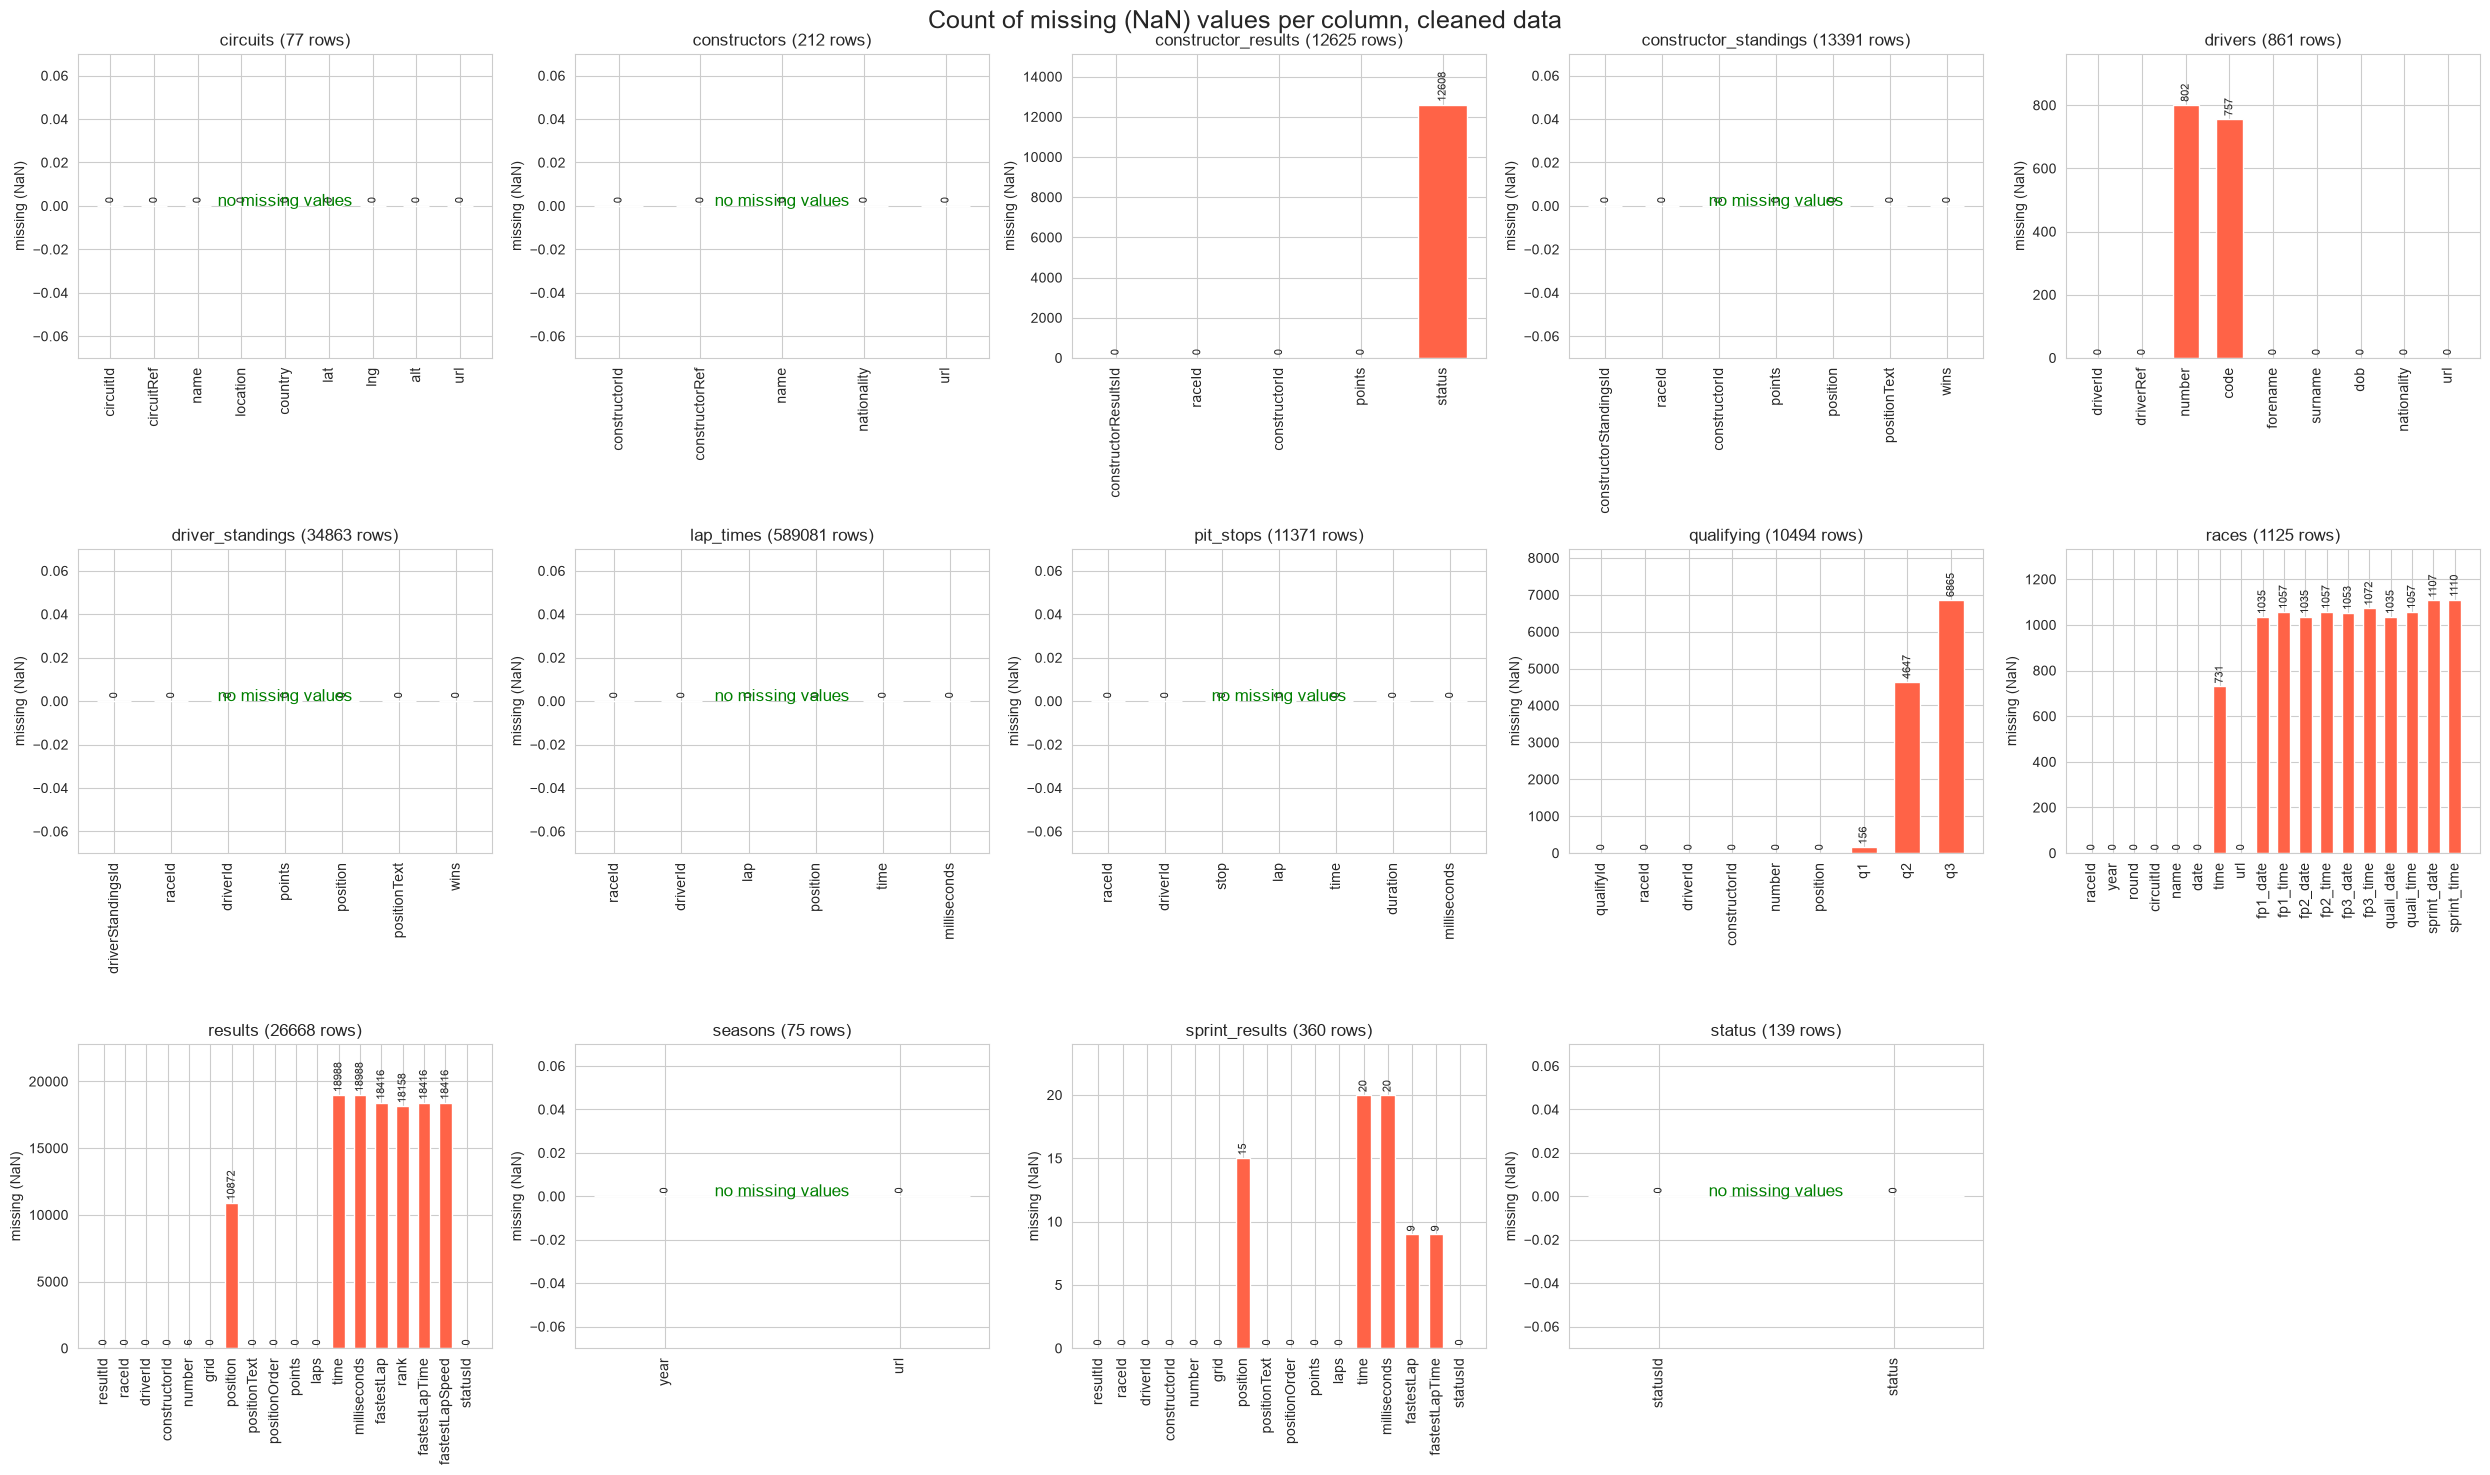

In [17]:
fig, axes = plt.subplots(3, 5, figsize=(25, 15))
axes = axes.flatten()   # turn the 3x5 grid into a simple list of 15 plots

i = 0
for name in clean:
    df = clean[name]
    ax = axes[i]

    # count how many cells in each column are missing (NaN)
    n_count = df.isnull().sum()

    bars = ax.bar(n_count.index, n_count.values, color="tomato", width=0.6)
    ax.bar_label(bars, fontsize=8, rotation=90, padding=2)
    ax.margins(y=0.2)


    ax.set_title(name + " (" + str(len(df)) + " rows)")
    ax.set_ylabel("missing (NaN)")
    ax.tick_params(axis="x", rotation=90)

    if n_count.sum() == 0:
        ax.text(0.5, 0.5, "no missing values", transform=ax.transAxes,
                ha="center", fontsize=12, color="green")

    i = i + 1

# we have 14 tables but 15 slots, so hide the last empty one
axes[14].axis("off")

plt.suptitle("Count of missing (NaN) values per column, cleaned data", fontsize=18)
plt.tight_layout()
plt.show()

Confirmed: the cleaning was done correctly. Every `\N` became a real missing value, and the bars match the raw `\N` plot, with two expected differences:
- `results` has 91 fewer rows (26,668 instead of 26,759), because the duplicate (raceId, driverId) rows were removed.
- `qualifying` q2 and q3 are slightly higher, because the real empty cells (22 and 46 rows) are now counted together with the former `\N` values.

### 3.2 What our target looks like
Our target is `podium = 1` if the driver finished 1st, 2nd or 3rd (`positionOrder <= 3`), else `0`. We add it to the clean results table, together with the race year (from `races`), since we look at the data per year below.

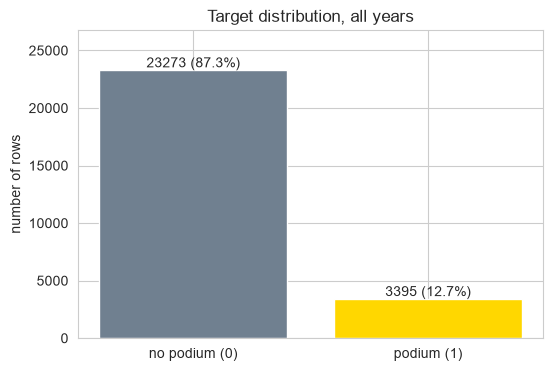

In [18]:
# add the year of each race to the results
res = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId")

# the target: 1 = podium, 0 = no podium
res["podium"] = (res["positionOrder"] <= 3).astype(int)

podium_counts = res["podium"].value_counts().sort_index()
podium_pct = podium_counts / len(res) * 100

plt.figure(figsize=(6, 4))
bars = plt.bar(["no podium (0)", "podium (1)"], podium_counts.values, color=["slategray", "gold"])
plt.bar_label(bars, labels=[str(podium_counts[0]) + " (" + str(round(podium_pct[0], 1)) + "%)",
                            str(podium_counts[1]) + " (" + str(round(podium_pct[1], 1)) + "%)"])
plt.title("Target distribution, all years")
plt.ylabel("number of rows")
plt.margins(y=0.15)
plt.show()

**Interpretation:** only about 12.7% of rows are podiums (3,395 of 26,668), so roughly 1 in 8. The target is **imbalanced**: a model that always says "no podium" would already be about 87% accurate while being useless. We keep this in mind when we choose metrics for the models (section 7).

### 3.3 Qualifying coverage per year
The F1 introduction document assumes `qualifying.csv` starts in the mid-1990s. To check this, we compute, for each year, the % of result rows that have a matching qualifying row (same raceId and driverId).

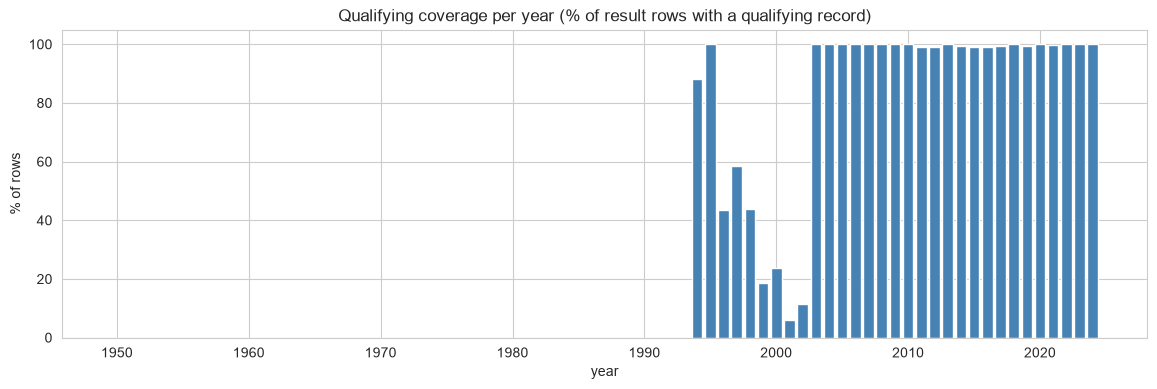

First year with qualifying data: 1994


In [19]:
# mark which result rows have a matching qualifying row
quali_pairs = clean["qualifying"][["raceId", "driverId"]].drop_duplicates()
quali_pairs["has_quali"] = 1

res = res.merge(quali_pairs, on=["raceId", "driverId"], how="left")
res["has_quali"] = res["has_quali"].fillna(0)

# the mean of a 0/1 column = the share of 1s, times 100 = percentage
quali_coverage = res.groupby("year")["has_quali"].mean() * 100

plt.figure(figsize=(14, 4))
plt.bar(quali_coverage.index, quali_coverage.values, color="steelblue")
plt.title("Qualifying coverage per year (% of result rows with a qualifying record)")
plt.xlabel("year")
plt.ylabel("% of rows")
plt.show()

print("First year with qualifying data:", quali_coverage[quali_coverage > 0].index.min())

**Interpretation:** the assumption is confirmed, qualifying data starts in **1994**.
- **1950–1993:** 0%, no qualifying data at all.
- **1994–1995:** almost complete.
- **1996–2002:** patchy (about 6% to 58%), so most drivers have no qualifying record.
- **2003–2024:** about 100% every year.

So qualifying-based features would only be reliable from 2003 onward. This is the "qualifying-coverage drift" mentioned in the brief. 
### 3.4 Podium rate and number of entries per year
Every race has exactly 3 podium places, so we expect years with more drivers per race to have a lower podium rate. We plot both per year, then put them against each other.

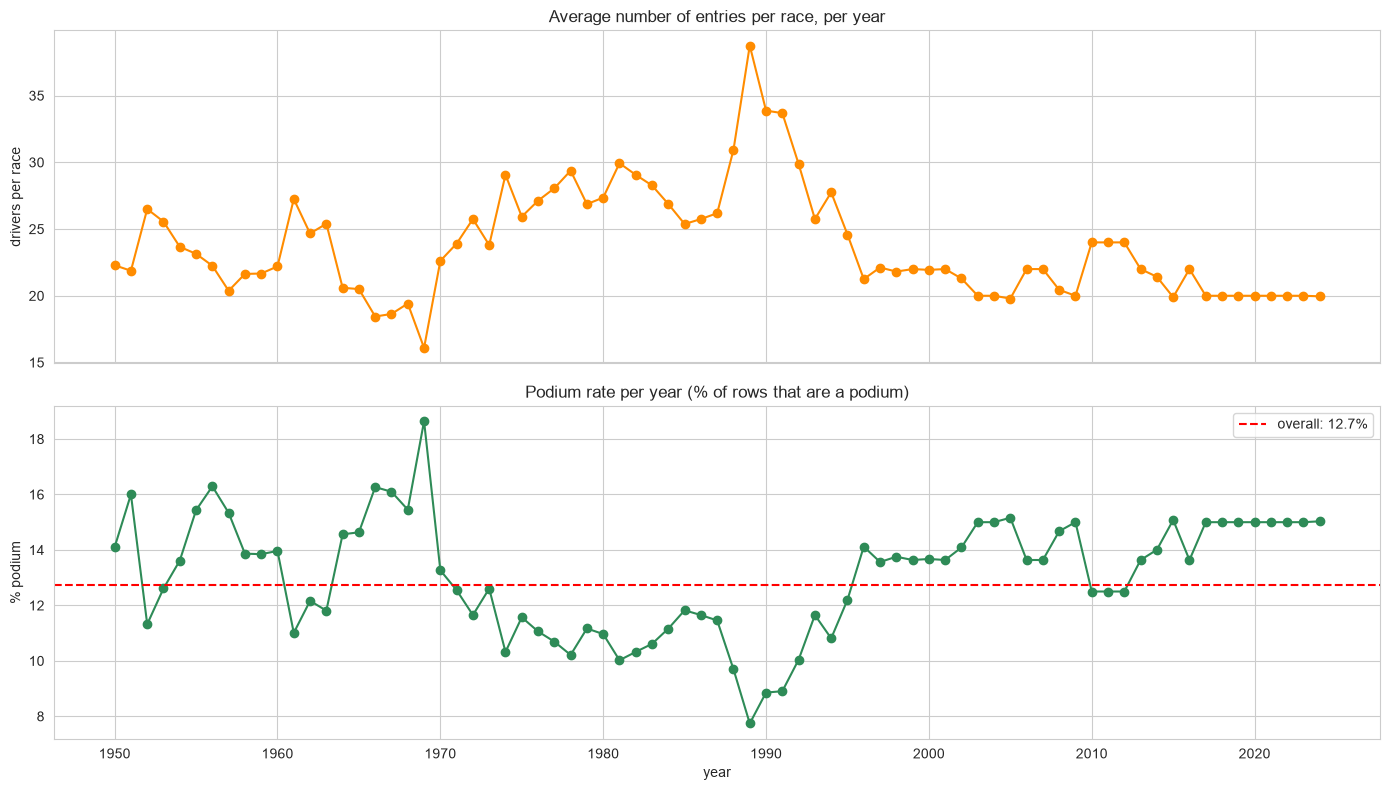

In [20]:
# average number of drivers per race, per year
entries = res.groupby(["year", "raceId"])["driverId"].count().reset_index()
entries.columns = ["year", "raceId", "entries"]
avg_entries = entries.groupby("year")["entries"].mean()

# podium rate per year
podium_rate = res.groupby("year")["podium"].mean() * 100
overall_rate = res["podium"].mean() * 100

# two plots on top of each other, sharing the same year axis
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(avg_entries.index, avg_entries.values, marker="o", color="darkorange")
axes[0].set_title("Average number of entries per race, per year")
axes[0].set_ylabel("drivers per race")

axes[1].plot(podium_rate.index, podium_rate.values, marker="o", color="seagreen")
axes[1].axhline(overall_rate, color="red", linestyle="--", label="overall: " + str(round(overall_rate, 1)) + "%")
axes[1].set_title("Podium rate per year (% of rows that are a podium)")
axes[1].set_ylabel("% podium")
axes[1].set_xlabel("year")
axes[1].legend()

plt.tight_layout()
plt.show()

As seen here, the higher the number of entries per race, the lower the podium rate for the drivers. The big spikes in entries all happened before the 2000s. Mixing years from these different eras would give the model rows with very different chances of a podium.

This finding, together with the qualifying coverage per year, led us to an important decision: we cut the training data down to **2003 onward**, where
1. the qualifying coverage for the drivers is almost 100% every year;
2. the field size is stable at about 20–24 cars per race, so the podium rate per year is also stable (about 12.5–15%) and does not vary much.

## 4. Answering 3 DE Questions

In this section we will answer the 3 DE questions, after reading the milestone and questions we will start first by creating one big table that has all the data so we can answer all questions. we will do left joins between the tables.

In [21]:
# start from results: one row = one driver in one race
de = clean['results'][['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'statusId']].copy()
print('rows before joins:', len(de))

rows before joins: 26668


In [22]:
#races : year and circuit
races=clean['races'][['raceId','year', 'circuitId']]
de=de.merge(races,on="raceId",how='left')

In [23]:
# circuits: circuit name and country
circuits = clean['circuits'][['circuitId', 'name', 'country']]
circuits = circuits.rename(columns={'name': 'circuit', 'country': 'circuit_country'})
de = de.merge(circuits, on='circuitId', how='left')

In [24]:
# qualifying: qualifying position
quali = clean['qualifying'][['raceId', 'driverId', 'position']]
quali = quali.rename(columns={'position': 'quali_position'})
de = de.merge(quali, on=['raceId', 'driverId'], how='left')

In [25]:
# drivers: nationality
drivers = clean['drivers'][['driverId', 'nationality']]
drivers = drivers.rename(columns={'nationality': 'driver_nationality'})
de = de.merge(drivers, on='driverId', how='left')

In [26]:
# constructors: team name
constructors = clean['constructors'][['constructorId', 'name']]
constructors = constructors.rename(columns={'name': 'constructor'})
de = de.merge(constructors, on='constructorId', how='left')

In [27]:
# status: finish / retirement reason as text
status = clean['status'][['statusId', 'status']]
de = de.merge(status, on='statusId', how='left')

In [28]:
print('rows after joins:', len(de)) # should be the same as before the check 
de.head(5)

rows after joins: 26668


,raceId,driverId,constructorId,grid,positionOrder,statusId,year,circuitId,circuit,circuit_country,quali_position,driver_nationality,constructor,status
0,1,1,1,18,20,2,2009,1,Albert Park Grand Prix Circuit,Australia,15.0,British,McLaren,Disqualified
1,1,2,2,9,10,1,2009,1,Albert Park Grand Prix Circuit,Australia,11.0,German,BMW Sauber,Finished
2,1,3,3,5,6,1,2009,1,Albert Park Grand Prix Circuit,Australia,5.0,German,Williams,Finished
3,1,4,4,10,5,1,2009,1,Albert Park Grand Prix Circuit,Australia,12.0,Spanish,Renault,Finished
4,1,5,1,12,19,4,2009,1,Albert Park Grand Prix Circuit,Australia,14.0,Finnish,McLaren,Collision


## Q1. 
Which circuits convert a front-row start into a podium most often, and does that ranking change after the 2014 hybrid era? Distinguish qualifying position from grid (which can differ due to penalties).  

The answer to this question all comes down to one number and that is , of the drivers who started on the front row (pos 1 or 2 )at a circuit , share finished on the podium

conversion rate=front-row starters who got a podium /all front row .
we will do that on the data cleaned data 2003-2024 because qualitifying data is onlt stable starting 2003.

In [29]:
q1=de[(de['year']>=2003) &(de['year']<=2024)].copy()

#targe 1 finished top3 
q1['podium']=(q1['positionOrder'] <=3).astype(int)

#era
q1['era']="before 2014"
q1.loc[q1['year'] >=2014 ,'era']="2014 and after"

# front row, two definitions: where he started vs where he qualified
q1['front_row_grid'] = q1['grid'].isin([1, 2])
q1['front_row_quali'] = q1['quali_position'].isin([1, 2])

In [30]:
print('rows:', len(q1))
q1[['year', 'circuit', 'grid', 'quali_position', 'positionOrder', 'podium', 'era', 'front_row_grid', 'front_row_quali']].head(10)

rows: 8970


,year,circuit,grid,quali_position,positionOrder,podium,era,front_row_grid,front_row_quali
0,2009,Albert Park Grand Prix Circuit,18,15.0,20,0,before 2014,False,False
1,2009,Albert Park Grand Prix Circuit,9,11.0,10,0,before 2014,False,False
2,2009,Albert Park Grand Prix Circuit,5,5.0,6,0,before 2014,False,False
3,2009,Albert Park Grand Prix Circuit,10,12.0,5,0,before 2014,False,False
4,2009,Albert Park Grand Prix Circuit,12,14.0,19,0,before 2014,False,False
5,2009,Albert Park Grand Prix Circuit,11,13.0,18,0,before 2014,False,False
6,2009,Albert Park Grand Prix Circuit,17,20.0,8,0,before 2014,False,False
7,2009,Albert Park Grand Prix Circuit,7,9.0,15,0,before 2014,False,False
8,2009,Albert Park Grand Prix Circuit,4,4.0,14,0,before 2014,False,False
9,2009,Albert Park Grand Prix Circuit,19,6.0,4,0,before 2014,False,False


what we did here was create a smaller table to use to asnwer q1 , now it was stated in the milstone that we need to distinguish qualifying from grid . so we wanna see actaully the difference between qualified but started back and the oppisite as well.

In [31]:
# how many front-row starts under each definition
print('front row by grid:      ', q1['front_row_grid'].sum())
print('front row by qualifying:', q1['front_row_quali'].sum())

# qualified P1-P2 but did NOT start there (grid penalty)
penalty = q1[(q1['front_row_quali'] == True) & (q1['front_row_grid'] == False)]
print('qualified on front row, started further back:', len(penalty))

# started P1-P2 but did NOT qualify there (moved up because of someone else's penalty)
promoted = q1[(q1['front_row_grid'] == True) & (q1['front_row_quali'] == False)]
print('started on front row, qualified further back:', len(promoted))


front row by grid:       854
front row by qualifying: 856
qualified on front row, started further back: 38
started on front row, qualified further back: 36


**Qualifying vs grid:** both definitions give about 2 front-row drivers per race (856 by qualifying, 854 by grid; in 2 races a front-row grid slot stayed empty, e.g. after a pit-lane start).
They disagree in about 4% of cases: 38 drivers qualified P1–P2 but started further back (grid penalty), and 36 started P1–P2 after qualifying lower (moved up by others' penalties).
So the two definitions mostly select the same drivers. We still compute the conversion rate with both and compare.


In [32]:
# grid definition: of the front-row starters, the share that finished on the podium
grid_front = q1[q1['front_row_grid'] == True]
print('Grid definition:')
print(grid_front.groupby('era')['podium'].mean())

# qualifying definition
quali_front = q1[q1['front_row_quali'] == True]
print()
print('Qualifying definition:')
print(quali_front.groupby('era')['podium'].mean())


Grid definition:
era
2014 and after    0.759912
before 2014       0.680000
Name: podium, dtype: float64

Qualifying definition:
era
2014 and after    0.736842
before 2014       0.672500
Name: podium, dtype: float64


**Overall:** across all circuits, a front-row start became a podium 68% of the time before 2014 and 76% from 2014 on (grid definition).
With the qualifying definition the rates are slightly lower (67% → 74%), because it also counts drivers who qualified on the front row but started further back after a grid penalty.
The gap between the two definitions is larger after 2014, when engine-related grid penalties became more common.


now lets see these numbers per circuit and era 

In [33]:
# per circuit and era: number of front-row starts and the share that became a podium
grid_rate = grid_front.groupby(['circuit', 'era'])['podium'].agg(['count', 'mean'])
grid_rate = grid_rate.reset_index()
grid_rate = grid_rate.rename(columns={'count': 'starts', 'mean': 'rate'})

grid_rate.head(20)


,circuit,era,starts,rate
0,Albert Park Grand Prix Circuit,2014 and after,18,0.722222
1,Albert Park Grand Prix Circuit,before 2014,22,0.590909
2,Autodromo Enzo e Dino Ferrari,2014 and after,8,0.750000
3,Autodromo Enzo e Dino Ferrari,before 2014,8,0.625000
4,Autodromo Internazionale del Mugello,2014 and after,2,1.000000
5,Autodromo Nazionale di Monza,2014 and after,22,0.727273
6,Autodromo Nazionale di Monza,before 2014,22,0.772727
7,Autódromo Hermanos Rodríguez,2014 and after,18,0.611111
8,Autódromo Internacional do Algarve,2014 and after,4,1.000000
9,Autódromo José Carlos Pace,2014 and after,19,0.789474


**Per-circuit comparison:** we put the two eras side by side (one row per circuit) and keep only circuits that were raced in both eras
with at least 10 front-row starts (5 races) in each. Circuits raced in only one era (e.g. Baku, Zandvoort, India) cannot be compared,
and circuits with very few starts give unreliable rates (e.g. Mugello: 2 starts, 100%). With 8 starts, one result already moves the rate by 12.5 points.


In [34]:
# split the table into the two eras
before = grid_rate[grid_rate['era'] == 'before 2014']
before = before[['circuit', 'starts', 'rate']]
before = before.rename(columns={'starts': 'starts_before', 'rate': 'rate_before'})

after = grid_rate[grid_rate['era'] == '2014 and after']
after = after[['circuit', 'starts', 'rate']]
after = after.rename(columns={'starts': 'starts_after', 'rate': 'rate_after'})

# one row per circuit; inner join keeps only circuits raced in BOTH eras
grid_table = before.merge(after, on='circuit', how='inner')
print('circuits in both eras:', len(grid_table))

# keep only circuits with enough front-row starts in each era
MIN_STARTS = 10
grid_table = grid_table[(grid_table['starts_before'] >= MIN_STARTS) & (grid_table['starts_after'] >= MIN_STARTS)]
print('circuits with at least', MIN_STARTS, 'starts in each era:', len(grid_table))

grid_table.sort_values('rate_after', ascending=False)


circuits in both eras: 21
circuits with at least 10 starts in each era: 14


,circuit,starts_before,rate_before,starts_after,rate_after
19,Suzuka Circuit,18,0.722222,18,0.888889
20,Yas Marina Circuit,10,0.600000,22,0.863636
7,Circuit de Monaco,22,0.772727,20,0.850000
8,Circuit de Spa-Francorchamps,18,0.722222,22,0.818182
6,Circuit de Barcelona-Catalunya,22,0.681818,22,0.818182
3,Autódromo José Carlos Pace,22,0.590909,19,0.789474
17,Shanghai International Circuit,20,0.650000,14,0.785714
5,Circuit Gilles Villeneuve,20,0.600000,18,0.777778
18,Silverstone Circuit,22,0.727273,24,0.750000
2,Autodromo Nazionale di Monza,22,0.772727,22,0.727273


**Answer (grid definition):** 14 circuits were raced in both eras with at least 10 front-row starts in each.
- **Before 2014** the best converters were Monaco and Monza (77%), followed by Silverstone, Suzuka and Spa (72–73%).
- **From 2014 on** the best were Suzuka (89%), Yas Marina (86%) and Monaco (85%).
- **The ranking changed:** Monaco is the only circuit near the top in both eras. Yas Marina (60% → 86%) and Interlagos (59% → 79%) moved up the most,
  while Monza (77% → 73%) and the Hungaroring (64% → 59%, last after 2014) were the only two to drop.
- 12 of 14 circuits converted at least as well after 2014, in line with the overall rise from 68% to 76%.
Note: with about 20 starts per era, one podium changes a rate by about 5 points, so small differences (e.g. Monza's drop = 1 podium) should not be over-interpreted.


In [35]:
# same as the grid table, but front row = qualifying position 1-2
quali_rate = quali_front.groupby(['circuit', 'era'])['podium'].agg(['count', 'mean'])
quali_rate = quali_rate.reset_index()
quali_rate = quali_rate.rename(columns={'count': 'starts', 'mean': 'rate'})

before = quali_rate[quali_rate['era'] == 'before 2014']
before = before[['circuit', 'starts', 'rate']]
before = before.rename(columns={'starts': 'starts_before', 'rate': 'rate_before'})

after = quali_rate[quali_rate['era'] == '2014 and after']
after = after[['circuit', 'starts', 'rate']]
after = after.rename(columns={'starts': 'starts_after', 'rate': 'rate_after'})

quali_table = before.merge(after, on='circuit', how='inner')
quali_table = quali_table[(quali_table['starts_before'] >= MIN_STARTS) & (quali_table['starts_after'] >= MIN_STARTS)]
print('circuits:', len(quali_table))

quali_table.sort_values('rate_after', ascending=False)


circuits: 14


,circuit,starts_before,rate_before,starts_after,rate_after
19,Suzuka Circuit,18,0.722222,18,0.888889
7,Circuit de Monaco,22,0.681818,20,0.850000
8,Circuit de Spa-Francorchamps,18,0.722222,22,0.818182
20,Yas Marina Circuit,10,0.600000,22,0.818182
6,Circuit de Barcelona-Catalunya,22,0.636364,22,0.818182
17,Shanghai International Circuit,20,0.700000,14,0.785714
18,Silverstone Circuit,22,0.772727,24,0.750000
2,Autodromo Nazionale di Monza,22,0.727273,22,0.727273
5,Circuit Gilles Villeneuve,20,0.600000,18,0.722222
0,Albert Park Grand Prix Circuit,22,0.590909,18,0.722222


**Qualifying definition:** the same 14 circuits and almost the same top 3 after 2014 (Suzuka 89%, Monaco 85%, then Spa, Yas Marina and Barcelona at 82%).
The definitions differ where front-row qualifiers took grid penalties: Monaco before 2014 converts 77% by grid but only 68% by qualifying,
and Interlagos after 2014 converts 79% by grid but only 65% by qualifying. So "front row by qualifying" also includes the cost of penalties,
while "front row by grid" measures only how well the actual starting position is kept.


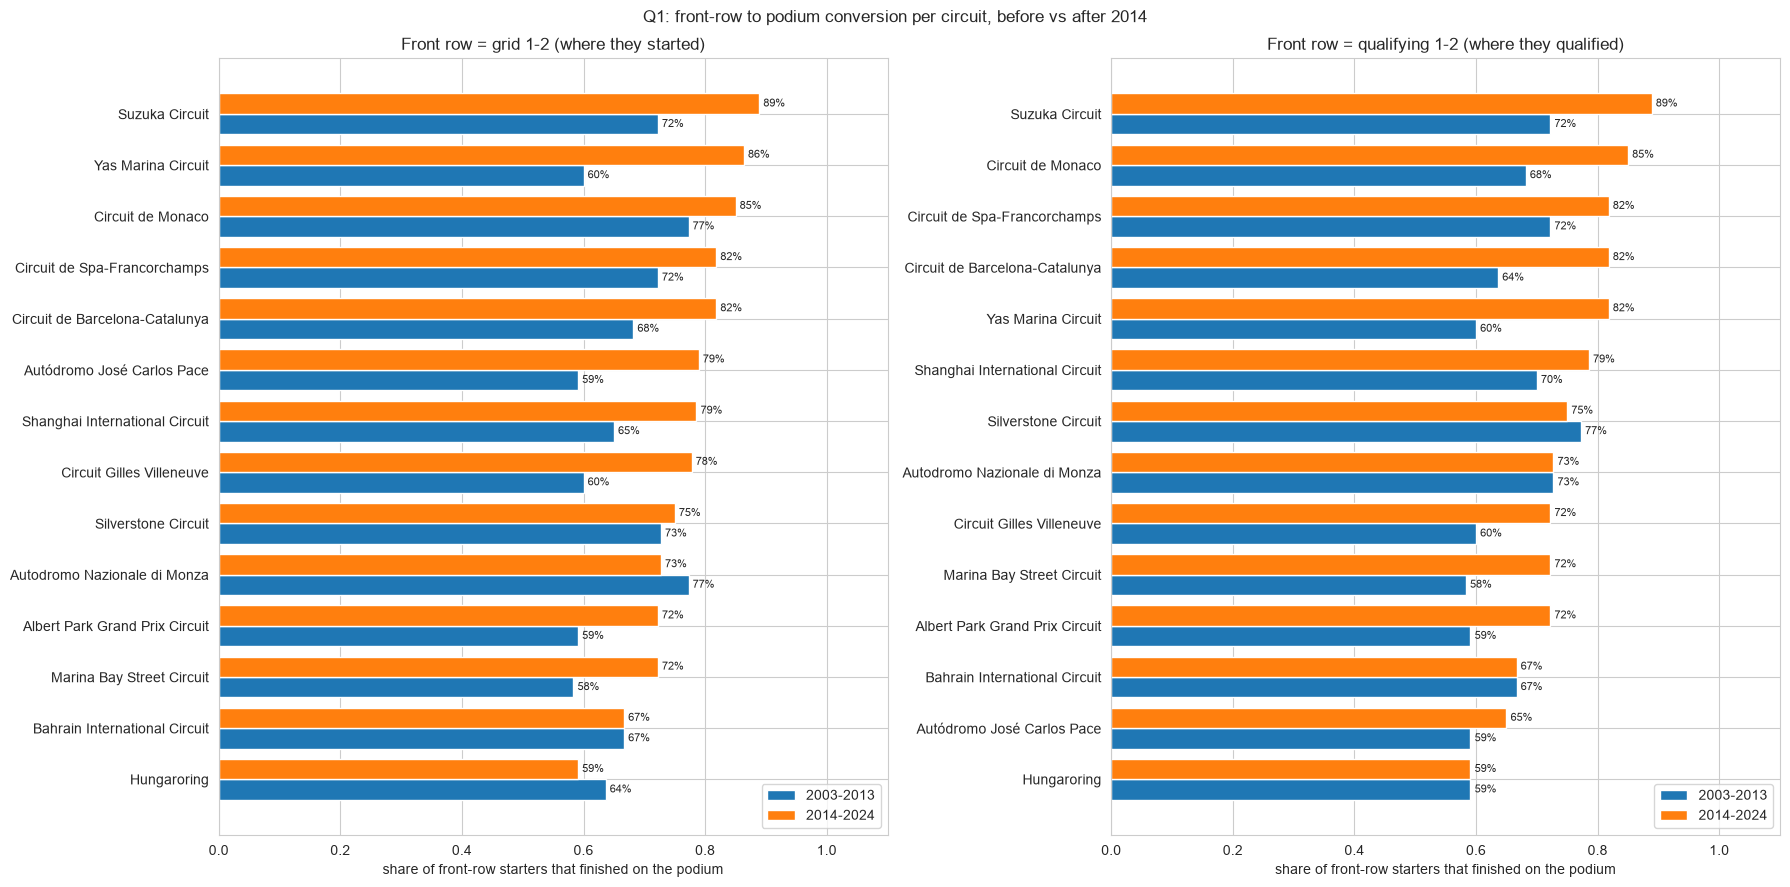

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

tables_to_plot = [grid_table, quali_table]
titles = ['Front row = grid 1-2 (where they started)', 'Front row = qualifying 1-2 (where they qualified)']

for i in range(2):
    ax = axes[i]
    table = tables_to_plot[i].sort_values('rate_after')
    y = np.arange(len(table))

    bars_before = ax.barh(y - 0.2, table['rate_before'], height=0.4, label='2003-2013')
    bars_after = ax.barh(y + 0.2, table['rate_after'], height=0.4, label='2014-2024')

    # write the percentage at the end of each bar
    labels_before = [str(round(v * 100)) + '%' for v in table['rate_before']]
    labels_after = [str(round(v * 100)) + '%' for v in table['rate_after']]
    ax.bar_label(bars_before, labels=labels_before, padding=3, fontsize=8)
    ax.bar_label(bars_after, labels=labels_after, padding=3, fontsize=8)

    ax.set_yticks(y)
    ax.set_yticklabels(table['circuit'])
    ax.set_xlim(0, 1.1)   # a bit of extra room so the labels fit
    ax.set_xlabel('share of front-row starters that finished on the podium')
    ax.set_title(titles[i])
    ax.legend(loc='lower right')

plt.suptitle('Q1: front-row to podium conversion per circuit, before vs after 2014')
plt.tight_layout()
plt.show()


### Q1 answer
**Which circuits convert a front-row start into a podium most often?** From 2014 on: Suzuka (89%), Yas Marina (86%) and Monaco (85%).
Before 2014: Monaco and Monza (77%), followed by Silverstone, Suzuka and Spa (72–73%) (grid definition).

**Does the ranking change after 2014?** Yes. Monaco is the only circuit near the top in both eras.
Yas Marina (60% → 86%) and Interlagos (59% → 79%) moved up the most, while Monza and the Hungaroring are the only circuits that dropped.
Overall, a front-row start became more valuable in the hybrid era (68% → 76%), and 12 of 14 circuits converted at least as well as before.

**Qualifying vs grid:** the two definitions disagree in about 4% of front-row cases (grid penalties). The rankings are mostly the same,
but where penalised front-row qualifiers were common, the qualifying-based rate is clearly lower:
Monaco before 2014 (77% grid vs 68% qualifying) and Interlagos after 2014 (79% vs 65%).

**Grain, missingness, cutoff:** one row = one driver in one race. We use 2003–2024, the years with complete qualifying data.
We compare only circuits raced in both eras with at least 10 front-row starts each (14 circuits). With about 20 starts per era,
one podium changes a rate by about 5 points, so small differences should not be over-interpreted.


## Q2.

Do drivers podium more often when racing at a circuit in their home country than elsewhere, after controlling for starting position (i.e., comparing drivers who started from similar grid positions, so the effect isn’t just because home drivers 
happen to qualify better)

to answer this we need to compare podium rates (podiums/starts), for drivers who started from similar grid psotions so we will make grid buckets 1-3,4-6,7-10,11-15 and 16+ and we will see later how to handle grid=0.

we also need to find what the cirucit countries are and the drivers nationality and map them (expected that some drivers dont race in their home country).



In [37]:
# Q2 uses the same years as Q1 (2003-2024)
q2 = de[(de['year'] >= 2003) & (de['year'] <= 2024)].copy()

# target: 1 = finished in the top 3
q2['podium'] = (q2['positionOrder'] <= 3).astype(int)

print('rows:', len(q2))
print()
print('driver nationalities:')
print(sorted(q2['driver_nationality'].unique()))
print()
print('circuit countries:')
print(sorted(q2['circuit_country'].unique()))


rows: 8970

driver nationalities:
['American', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chinese', 'Colombian', 'Danish', 'Dutch', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Russian', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Venezuelan']

circuit countries:
['Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'Spain', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


we created the table for q2 from de , we extracted the unqiue nationalities and countries , also two problems where found.

1. argentinian has an extra space 
2. nationalities and countires are diff (ex. american and united states )

In [38]:
# fix the two text problems
q2['driver_nationality'] = q2['driver_nationality'].str.strip()
q2['circuit_country'] = q2['circuit_country'].replace('United States', 'USA')

# nationality -> country, written the same way as circuit_country
# (only nationalities that have a circuit in 2003-2024)
nationality_to_country = {
    'American': 'USA',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chinese': 'China',
    'Dutch': 'Netherlands',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'Portuguese': 'Portugal',
    'Russian': 'Russia',
    'Spanish': 'Spain',
}

# nationalities not in the dictionary become NaN (no home race)
q2['driver_country'] = q2['driver_nationality'].map(nationality_to_country)

# home race = the driver's country is the circuit's country
q2['is_home'] = q2['driver_country'] == q2['circuit_country']

print(q2['is_home'].value_counts())


is_home
False    8605
True      365
Name: count, dtype: int64


In [39]:
# grid = 0 means the driver started from the pit lane (behind everyone), so it gets its own bucket
print('pit-lane starts:', (q2['grid'] == 0).sum())

# bins=[-1, 0, 3, 6, 10, 15, 30] means: 0, 1-3, 4-6, 7-10, 11-15, 16 and further back
q2['grid_bucket'] = pd.cut(q2['grid'], bins=[-1, 0, 3, 6, 10, 15, 30],
                           labels=['pit lane', 'P1-3', 'P4-6', 'P7-10', 'P11-15', 'P16+'])

# how many home and away starts fall in each bucket
pd.crosstab(q2['grid_bucket'], q2['is_home'])


pit-lane starts: 86


is_home,False,True
grid_bucket,,
pit lane,85,1
P1-3,1221,61
P4-6,1236,48
P7-10,1632,76
P11-15,2048,85
P16+,2383,94


In [40]:
# podium rate = mean of the 0/1 podium column = podiums / starts
rates = q2.pivot_table(index='grid_bucket', columns='is_home', values='podium',
                       aggfunc='mean', observed=False)
rates = rates.rename(columns={False: 'away_rate', True: 'home_rate'})

# positive = home drivers reach the podium more often from the same grid bucket
rates['difference'] = rates['home_rate'] - rates['away_rate']

rates


is_home,away_rate,home_rate,difference
grid_bucket,,,
pit lane,0.000000,0.000000,0.000000
P1-3,0.653563,0.606557,-0.047005
P4-6,0.226537,0.229167,0.002629
P7-10,0.056373,0.026316,-0.030057
P11-15,0.018555,0.011765,-0.006790
P16+,0.010071,0.010638,0.000567


In [41]:
# number of home starts and actual home podiums in each bucket
home = q2[q2['is_home'] == True]
home_starts = home.groupby('grid_bucket', observed=False)['podium'].count()
home_podiums = home.groupby('grid_bucket', observed=False)['podium'].sum()

# expected = home starts x the away podium rate of the same bucket
expected_podiums = home_starts * rates['away_rate']

print('home podiums, actual:  ', home_podiums.sum())
print('home podiums, expected:', round(expected_podiums.sum(), 1))
print()

# for comparison: the simple home vs away rate, WITHOUT controlling for grid
print('home rate, no grid control:', round(home['podium'].mean() * 100, 1), '%')
print('away rate, no grid control:', round(q2[q2['is_home'] == False]['podium'].mean() * 100, 1), '%')


home podiums, actual:   52
home podiums, expected: 57.5

home rate, no grid control: 14.2 %
away rate, no grid control: 14.3 %


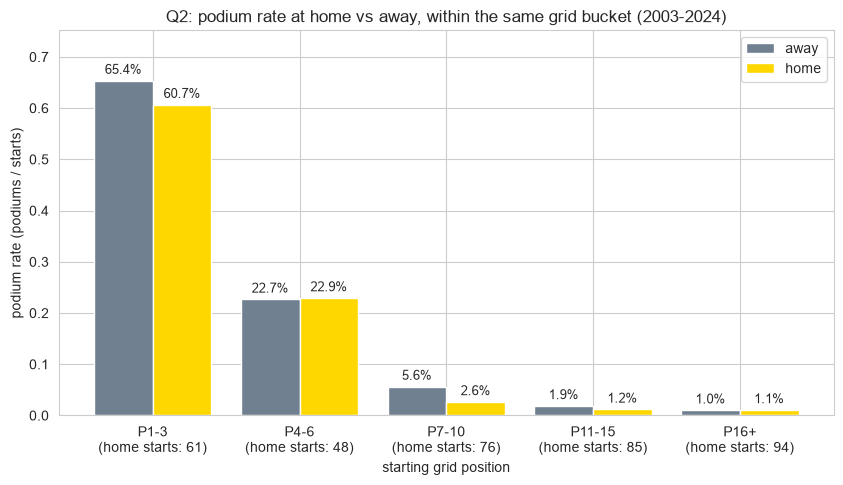

In [42]:
# leave out the pit-lane bucket (only 1 home start, no meaningful rate)
plot_rates = rates.drop('pit lane')
plot_home_starts = home_starts.drop('pit lane')

x = np.arange(len(plot_rates))

plt.figure(figsize=(10, 5))
bars_away = plt.bar(x - 0.2, plot_rates['away_rate'], width=0.4, color='slategray', label='away')
bars_home = plt.bar(x + 0.2, plot_rates['home_rate'], width=0.4, color='gold', label='home')

# write the percentage on top of each bar
labels_away = [str(round(v * 100, 1)) + '%' for v in plot_rates['away_rate']]
labels_home = [str(round(v * 100, 1)) + '%' for v in plot_rates['home_rate']]
plt.bar_label(bars_away, labels=labels_away, padding=3, fontsize=9)
plt.bar_label(bars_home, labels=labels_home, padding=3, fontsize=9)

# x labels: bucket name + number of home starts, so the reader sees how small the home groups are
tick_labels = []
for bucket in plot_rates.index:
    tick_labels.append(bucket + '\n(home starts: ' + str(plot_home_starts[bucket]) + ')')
plt.xticks(x, tick_labels)

plt.ylabel('podium rate (podiums / starts)')
plt.xlabel('starting grid position')
plt.title('Q2: podium rate at home vs away, within the same grid bucket (2003-2024)')
plt.legend()
plt.margins(y=0.15)
plt.show()


### Q2 answer
**Do drivers podium more often at their home circuit, after controlling for starting position?** No. We found no home advantage.

**Method:** a race counts as a home race when the driver's nationality matches the circuit's country (e.g. "British" → "UK"; we merged "United States" into "USA" and removed a trailing space in "Argentinian").
To control for starting position, we grouped starts into grid buckets (P1–3, P4–6, P7–10, P11–15, P16+, and pit lane for grid = 0) and compared the podium rate (podiums / starts) of home and away drivers **within each bucket**.

**Results:**
- Within every bucket the home and away rates are almost the same: P1–3 61% home vs 65% away, P4–6 23% vs 23%, and very small rates further back.
- **Expected vs actual:** if home drivers did as well as away drivers from the same buckets, they would have reached about 57.5 podiums. They actually reached 52.
- Without the grid control the two groups look identical (14.2% home vs 14.3% away). This hides the fact that home drivers started from P1–3 slightly more often (17% of home starts vs 14% of away starts). Taking that into account, they did slightly worse than expected, not better.

The gap (about 5 podiums over 22 seasons) is too small to count as a real effect. In P1–3, for example, one podium more or less changes the home rate by 1.6 points. So the answer is **no evidence of a home advantage**, not "home drivers do worse".

**Grain, missingness, cutoff:** one row = one driver in one race, 2003–2024 (the same window as Q1 and the model). Only 365 of 8,970 starts are home starts (about 4%), because 12 nationalities (e.g. Finnish, Danish, Swiss) have no circuit in their country. Those drivers count as away in all their races.
The pit-lane bucket has only 1 home start, so it is not compared. Grid position is known before the race, so the comparison uses only pre-race information plus the target.


## Q3. 
Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 
2022–2024?  

In [43]:
# Q3 compares 2014-2021 with 2022-2024
q3 = de[(de['year'] >= 2014) & (de['year'] <= 2024)].copy()

q3['era'] = '2014-2021'
q3.loc[q3['year'] >= 2022, 'era'] = '2022-2024'

print('rows:', len(q3))
print(q3['era'].value_counts())
print()

# every status in these years and how often it appears
print(q3['status'].value_counts().to_string())


rows: 4626
era
2014-2021    3267
2022-2024    1359
Name: count, dtype: int64

status
Finished            2403
+1 Lap              1178
+2 Laps              208
Collision            150
Accident              85
Engine                81
Collision damage      59
Retired               50
Brakes                49
Power Unit            42
Gearbox               42
Suspension            25
+3 Laps               24
Hydraulics            15
Electrical            14
Withdrew              14
Power loss            13
Disqualified          11
Wheel                 11
Spun off              11
Oil leak              10
Overheating            8
Mechanical             7
Water pressure         7
Puncture               7
Turbo                  6
+4 Laps                6
ERS                    5
Exhaust                5
Battery                5
Fuel pressure          5
Water leak             4
Electronics            4
Tyre                   4
Undertray              4
Rear wing              3
Transmission   

In [44]:
# statuses where a part of the car failed (not a crash, the driver or the rules)
mechanical_statuses = [
    'Engine', 'Power Unit', 'Power loss', 'Turbo', 'ERS', 'Battery', 'Spark plugs',
    'Gearbox', 'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential',
    'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Hydraulics',
    'Electrical', 'Electronics', 'Throttle', 'Technical', 'Mechanical', 'Vibrations',
    'Oil leak', 'Oil pressure', 'Overheating', 'Water pressure', 'Water leak',
    'Water pump', 'Radiator', 'Cooling system', 'Exhaust',
    'Fuel pressure', 'Fuel leak', 'Fuel system', 'Fuel pump',
]

# 1 = mechanical retirement, 0 = anything else
q3['mechanical'] = q3['status'].isin(mechanical_statuses).astype(int)

print('mechanical statuses in the list:', len(mechanical_statuses))
print('mechanical retirements:', q3['mechanical'].sum(), 'of', len(q3), 'starts')
print(q3.groupby('era')['mechanical'].mean())


mechanical statuses in the list: 37
mechanical retirements: 377 of 4626 starts
era
2014-2021    0.091827
2022-2024    0.056659
Name: mechanical, dtype: float64


In [45]:
# per era and constructor: starts, mechanical retirements, and the rate
team_rate = q3.groupby(['era', 'constructor'])['mechanical'].agg(['count', 'sum', 'mean'])
team_rate = team_rate.reset_index()
team_rate = team_rate.rename(columns={'count': 'starts', 'sum': 'mech_dnf', 'mean': 'rate'})

# teams with very few starts give unreliable rates, so keep only teams with at least one full season
MIN_TEAM_STARTS = 40
team_rate = team_rate[team_rate['starts'] >= MIN_TEAM_STARTS]

# highest rates first, shown separately for each era
before = team_rate[team_rate['era'] == '2014-2021'].sort_values('rate', ascending=False)
after = team_rate[team_rate['era'] == '2022-2024'].sort_values('rate', ascending=False)

print('2014-2021:')
print(before.to_string(index=False))
print()
print('2022-2024:')
print(after.to_string(index=False))


2014-2021:
      era    constructor  starts  mech_dnf     rate
2014-2021       Lotus F1      76        13 0.171053
2014-2021     Toro Rosso     242        39 0.161157
2014-2021        McLaren     320        44 0.137500
2014-2021        Renault     200        27 0.135000
2014-2021         Sauber     200        22 0.110000
2014-2021       Red Bull     320        34 0.106250
2014-2021     AlphaTauri      78         8 0.102564
2014-2021   Racing Point      76         7 0.092105
2014-2021   Haas F1 Team     244        18 0.073770
2014-2021       Williams     320        23 0.071875
2014-2021 Alpine F1 Team      44         3 0.068182
2014-2021 Manor Marussia      78         5 0.064103
2014-2021    Force India     200        12 0.060000
2014-2021        Ferrari     320        17 0.053125
2014-2021       Mercedes     320        12 0.037500
2014-2021     Alfa Romeo     120         4 0.033333
2014-2021   Aston Martin      44         1 0.022727

2022-2024:
      era    constructor  starts  mech_dn

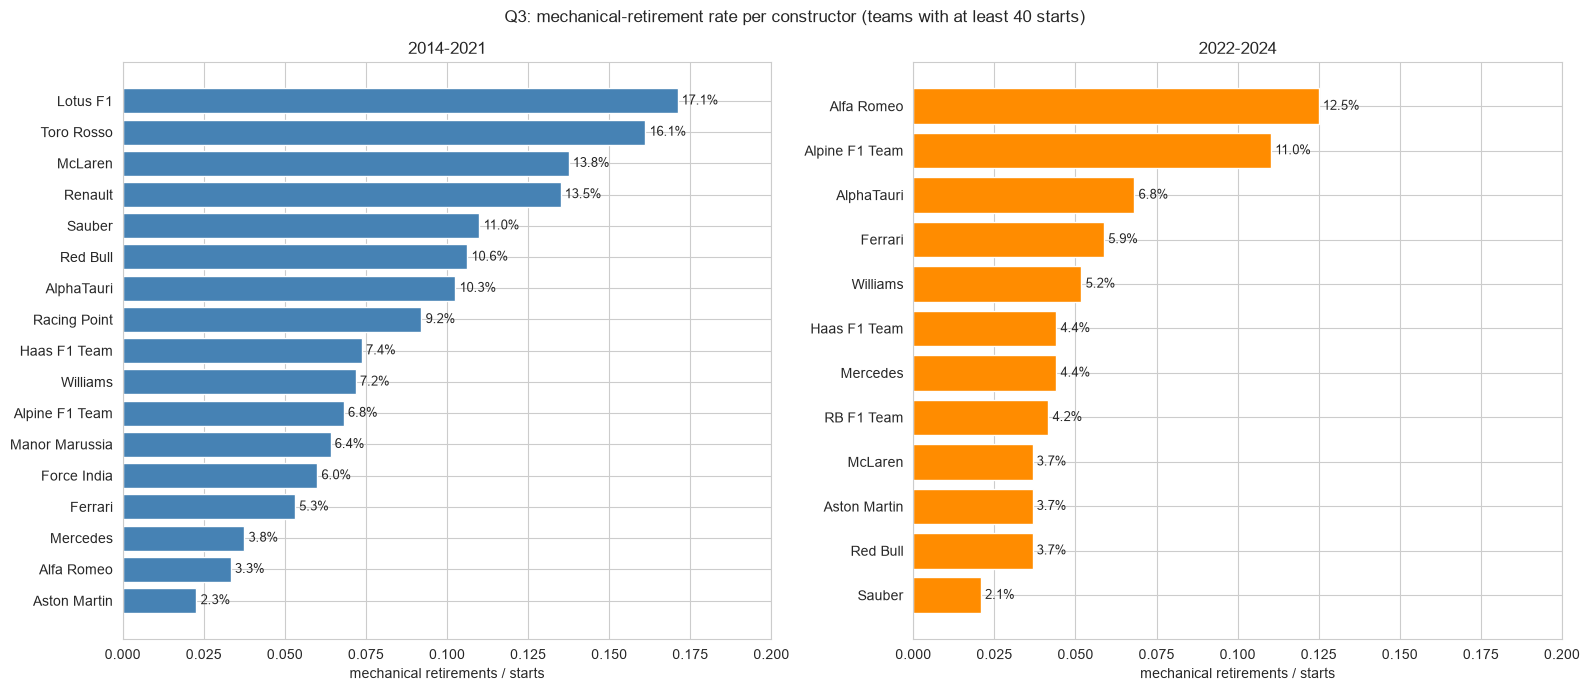

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

tables_to_plot = [before, after]
titles = ['2014-2021', '2022-2024']
colors = ['steelblue', 'darkorange']

for i in range(2):
    ax = axes[i]
    table = tables_to_plot[i].sort_values('rate')   # lowest at the bottom, highest on top

    bars = ax.barh(table['constructor'], table['rate'], color=colors[i])

    labels = [str(round(v * 100, 1)) + '%' for v in table['rate']]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=9)

    ax.set_xlim(0, 0.2)   # same scale on both plots so they can be compared
    ax.set_xlabel('mechanical retirements / starts')
    ax.set_title(titles[i])

plt.suptitle('Q3: mechanical-retirement rate per constructor (teams with at least 40 starts)')
plt.tight_layout()
plt.show()


### Q3 answer
**Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?**
- **2014–2021:** Lotus F1 (17%), Toro Rosso (16%), McLaren (14%) and Renault (14%). Mercedes was the most reliable (3.8%).
- **2022–2024:** Alfa Romeo (12.5%) and Alpine (11%). All other teams are at 7% or below, and Red Bull, McLaren and Aston Martin share the lowest rate (3.7%).

Overall the cars became more reliable: the mechanical rate fell from 9.2% to 5.7% of starts. The ranking also changed. McLaren (14% → 3.7%) and Red Bull (11% → 3.7%) improved the most, while Alpine (the renamed Renault team) stayed near the top.

**Method:** rate = mechanical retirements / starts, per constructor and era. We counted a retirement as mechanical when a part of the car failed by itself (37 statuses, e.g. Engine, Power Unit, Gearbox, Brakes, Hydraulics; full list in `mechanical_statuses`).
Not counted: finishes (+N Laps), crashes (Collision, Accident, Spun off, ...), rule or driver reasons (Disqualified, Withdrew, Illness), and unclear statuses (Retired with no reason, Puncture, Tyre, Wheel, Wheel nut, wings, Undertray, Out of fuel), which can come from contact, debris or pit-stop errors. These are about 100 rows, so they barely change the rates.

**Grain, missingness, cutoff:** one row = one driver in one race, 2014–2024 (4,626 starts). We kept teams with at least 40 starts (about one full season) in an era. Constructors are grouped by the name in the dataset, so rebrands count as separate teams (e.g. Force India → Racing Point → Aston Martin, Toro Rosso → AlphaTauri → RB).
With about 136 starts per team in 2022–2024, one failure changes a rate by about 0.7 points, so small differences in the middle of the ranking should not be over-interpreted. The retirement status is known only after the race, so this is an analysis question, not a model feature.
